# **Advanced Optimization Techniques for Nonlinear Regression and Decision-Making Under Uncertainty**

**Work completed by: Juan del Mazo Vázquez**

This work aims to develop and analyze advanced optimization techniques for two distinct topics: Nonlinear Optimization and Optimization under Uncertainty.

The study is divided into two major sections. The first section focuses on estimating regression coefficients in a predefined linear regression model by employing various optimization methods, including regularized approaches and constrained minimization. The second section addresses the stochastic farmer problem, incorporating uncertainty into decision-making using Pyomo, along with concepts like the Expected Value of Perfect Information (EVPI) and the Value of the Stochastic Solution (VSS).

To ensure clarity and efficiency, the Python code is executed sequentially and avoids unnecessary repetition, such as re-importing libraries in multiple sections. This structure enhances readability and supports a logical flow, facilitating the interpretation and execution of the methodologies. The notebook is structured to provide a clear understanding of the concepts, algorithms, and results presented.

## **Nonlinear Optimization: Regularized Regression and Constrained Minimization**

### **Introduction**

This section explores the application of nonlinear optimization techniques to solve a high-dimensional regression problem. The objective is to estimate regression coefficients for a predefined linear regression model with $K = 150$ independent variables and $n = 1500$ observations. The model is defined as:

$$
Y = X\beta + \epsilon
$$

where:

- $X = (X_1, X_2, \dots, X_K)$ represents the independent variables.

- $\beta = (\beta_0, \beta_1, \dots, \beta_K)^T$ are the regression coefficients, constrained within the range [-5, 5].

- $\epsilon$ is the noise term.

**Optimization Problem**:

The task involves solving a **regularized regression problem** using a fourth-order regularization method. The optimization objective is given by:

$$
\min_{\beta} \frac{1}{n} \sum_{i=1}^{n} (y_i - x_i\beta)^2 + \rho \sum_{j=0}^{K} \beta_j^4
$$

where $\rho$ is the regularization parameter that controls the trade-off between model flexibility and regularization strength. Various values of $\rho$ $(0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100)$ are analyzed to evaluate its impact on the estimated coefficients and model behavior.

In addition, a **constrained optimization problem** is considered:

$$
\min_{\beta} \frac{1}{n} \sum_{i=1}^{n} (y_i - x_i\beta)^2
$$

Subject to:

$$
\sum_{j=0}^{K} \beta_j^2 = 1
$$

**Optimization Techniques**:

To address these tasks, multiple nonlinear optimization techniques are implemented and compared:

1. **Direct Optimization with Solvers** (from the `scipy.optimize` module):
   
   - **BFGS**
   
   - **L-BFGS-B**
   
   - **CG**
   
   - **Newton-CG**
   
   - **TNC**
   
   - **SLSQP**

   These solvers are evaluated based on their performance in terms of:
   
   - Iterations
   
   - Function evaluations
   
   - Gradient and Hessian evaluations
   
   - Execution time

2. **Custom Implementations of Optimization Methods**:
   
   - **Gradient Method**: A basic first-order optimization approach.
   
   - **Newton Method**: A second-order optimization method leveraging the
   Hessian.
   
   - **Quasi-Newton Method**: A practical alternative to Newton's method using
   approximate second-order information.
   
   - **Coordinate Gradient Method**: Updates one coefficient at a time in each
   iteration.
   
   - **Mini-Batch Gradient Method**: Processes subsets of data for
   computational efficiency, exploring the impact of mini-batch size on
   performance.
   
   - **Subsampled Hessian-Free Inexact Method**: An advanced technique leveraging subsampled data for computational efficiency.

3. **Constrained Optimization**:
   
   - A **Penalization Algorithm** is implemented to incorporate the L2-norm constraint $(\|\beta\|_2 = 1)$ into the objective function using a penalty term.
   
   - The **SLSQP** solver is used to explicitly enforce the L2-norm constraint.

**Evaluation Metrics**:

The optimization techniques are assessed based on:

- **Computational Performance**: Number of iterations, function/gradient
evaluations, and execution time.

- **Predictive Accuracy**: Mean Absolute Error (MAE) and $R^2$ scores.

- **Regularization Impact**: Behavior of coefficients under varying regularization strengths $(\rho)$.

The goal of this analysis is to thoroughly explore the trade-offs between computational efficiency, predictive performance, and constraint satisfaction in high-dimensional regression contexts. By comparing multiple approaches and solvers, the study provides insights into the strengths and limitations of each method, particularly under varying regularization and constraint scenarios.

### **Nonlinear Optimization: Evaluating Solvers for Regularized Regression Models**

**Data Generation**:

To ensure robustness and comprehensiveness in this analysis, synthetic data was generated, exceeding the given requirements. Specifically, $(K = 150)$ independent variables and $(n = 1500)$ observations were considered. The regression model is expressed as:

$$
Y = X\beta + \epsilon
$$

where:

- $X$ is a matrix of size $n \times K$ representing the independent variables, with values randomly sampled from a uniform distribution between 0 and 1.

- $\beta$ is a vector of true coefficients, randomly generated within the range $[-5, 5]$.

- $\epsilon$ is a noise vector sampled from a standard normal distribution, simulating random noise in the model.

The synthetic data was generated in Python using the following implementation:

In [ ]:
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

# Define dimensions
n, K = 1500, 150

# Generate data
X = np.random.rand(n, K)  # Random independent variables
beta_true = np.random.uniform(-5, 5, K)  # True coefficients within [-5, 5]
epsilon = np.random.normal(0, 1, n)  # Noise term
Y = X @ beta_true + epsilon  # Dependent variable

# Print data summary
print(f"Generated data with {n} observations and {K} variables.")

Generated data with 1500 observations and 150 variables.


**Problem Formulation**:

The optimization objective is to minimize the following function:

$$
\min_{\beta} \frac{1}{n} \sum_{i=1}^{n} (y_i - x_i\beta)^2 + \rho \sum_{j=0}^{K} \beta_j^4
$$

where:

- $\rho$ is a regularization parameter that penalizes large values of $\beta$, ensuring regularization and preventing overfitting. Multiple values of $\rho$ are explored in this analysis: $\rho = 0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100$.

The term $\rho \sum_{j=0}^{K} \beta_j^4$ imposes a fourth-order penalty on the coefficients, discouraging excessively large values and improving model generalization. This allows the model to balance between fitting the data accurately and maintaining simplicity by penalizing larger coefficients.

To facilitate the use of solvers that require gradient and Hessian information, these components are derived and implemented in Python as follows:

In [ ]:
# Objective function
def objective(beta, *args):
    X, Y, rho = args
    residuals = Y - X @ beta
    return (1 / n) * np.sum(residuals ** 2) + rho * np.sum(beta ** 4)

# Gradient of the objective function
def gradient(beta, *args):
    global gradient_calls
    gradient_calls += 1
    X, Y, rho = args
    residuals = Y - X @ beta
    grad = (-2 / n) * X.T @ residuals + 4 * rho * beta ** 3
    return grad

# Hessian-product function for Newton-CG
def hessp(beta, p, *args):
    global hessian_calls
    hessian_calls += 1
    X, Y, rho = args
    hess = (2 / n) * (X.T @ (X @ p)) + 12 * rho * (beta ** 2) * p
    return hess

# Global counters for gradient and Hessian evaluations
gradient_calls = 0
hessian_calls = 0

# Function to reset counters
def reset_counters():
    global gradient_calls, hessian_calls
    gradient_calls = 0
    hessian_calls = 0

**Optimization Using `scipy.optimize.minimize`**:

Six solvers were utilized: `BFGS`, `L-BFGS-B`, `CG`, `Newton-CG`, `TNC`, and `SLSQP`. These solvers were chosen for their widespread use and compatibility with gradient-based optimization. Each solver's performance was evaluated based on the following criteria:

- **Number of iterations**

- **Function evaluations**

- **Gradient evaluations**

- **Hessian evaluations** (when applicable)
- **Computational time**

- **Prediction performance** (Mean Absolute Error (MAE), and $R^2$)

The following code executes the optimization for each solver and collects performance metrics:

In [ ]:
import pandas as pd
pd.set_option('display.max_colwidth', None)
import numpy as np
from scipy.optimize import minimize
from sklearn.metrics import mean_absolute_error, r2_score
import time

# Define the range of regularization parameters (rho)
rho_values = [0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100]

# Define the list of solvers to test
solvers = ['BFGS', 'L-BFGS-B', 'CG', 'Newton-CG', 'TNC', 'SLSQP']

# Store results
results_rho = []

# Loop through each value of rho and solver
for rho in rho_values:
    for solver in solvers:
        reset_counters()  # Reset gradient and Hessian counters before each run

        # Print the current solver and rho being tested
        print(f"Optimizing with Solver = {solver}, Rho = {rho}")

        # Start timing
        start_time = time.time()

        # Perform optimization
        if solver == 'Newton-CG':
            res = minimize(
                objective,
                x0=np.zeros(K),  # Initial guess
                args=(X, Y, rho),  # Pass X, Y, and rho as arguments
                method=solver,
                jac=gradient,  # Use gradient
                hessp=hessp  # Use Hessian-vector product for Newton-CG
            )
        else:
            res = minimize(
                objective,
                x0=np.zeros(K),  # Initial guess
                args=(X, Y, rho),  # Pass X, Y, and rho as arguments
                method=solver,
                jac=gradient if solver != 'L-BFGS-B' else None  # Gradient not required for L-BFGS-B
            )

        # End timing
        elapsed_time = time.time() - start_time

        # Predictions using the optimized coefficients
        Y_pred = X @ res.x

        # Calculate performance metrics
        mae = mean_absolute_error(Y, Y_pred)
        r2 = r2_score(Y, Y_pred)
        final_objective = objective(res.x, X, Y, rho)

        # Append results
        results_rho.append({
            'Solver': solver,
            'Rho': rho,
            'Final Objective': final_objective,
            'MAE': mae,
            'R-squared': r2,
            'Iterations': res.nit if 'nit' in res else 'N/A',
            'Func Evaluations': res.nfev if 'nfev' in res else 'N/A',
            'Gradient Evaluations': gradient_calls,
            'Hessian Evaluations': hessian_calls if solver == 'Newton-CG' else 'N/A',
            'Time (s)': elapsed_time,
            'Success': res.success
        })

# Convert results to a DataFrame for visualization and analysis
results_rho_df = pd.DataFrame(results_rho)

# Display the results
print("\nOptimization Results:")
print(results_rho_df)

Optimizing with Solver = BFGS, Rho = 1e-05
Optimizing with Solver = L-BFGS-B, Rho = 1e-05
Optimizing with Solver = CG, Rho = 1e-05
Optimizing with Solver = Newton-CG, Rho = 1e-05
Optimizing with Solver = TNC, Rho = 1e-05
Optimizing with Solver = SLSQP, Rho = 1e-05
Optimizing with Solver = BFGS, Rho = 0.0001
Optimizing with Solver = L-BFGS-B, Rho = 0.0001
Optimizing with Solver = CG, Rho = 0.0001
Optimizing with Solver = Newton-CG, Rho = 0.0001
Optimizing with Solver = TNC, Rho = 0.0001
Optimizing with Solver = SLSQP, Rho = 0.0001
Optimizing with Solver = BFGS, Rho = 0.001
Optimizing with Solver = L-BFGS-B, Rho = 0.001
Optimizing with Solver = CG, Rho = 0.001
Optimizing with Solver = Newton-CG, Rho = 0.001
Optimizing with Solver = TNC, Rho = 0.001
Optimizing with Solver = SLSQP, Rho = 0.001
Optimizing with Solver = BFGS, Rho = 0.01
Optimizing with Solver = L-BFGS-B, Rho = 0.01
Optimizing with Solver = CG, Rho = 0.01
Optimizing with Solver = Newton-CG, Rho = 0.01
Optimizing with Solver =

**Results**:

The following table summarizes the optimization results for all solvers across different values of $\rho$:

Solver      | $\rho$       | Final Objective | MAE       | $R^2$      | Iterations | Func Evaluations | Gradient Evaluations | Hessian Evaluations | Time (s)
-------------|--------------|-----------------|-----------|------------|------------|------------------|-----------------------|---------------------|----------
BFGS        | 0.00001      | 1.036398        | 0.741119  | 0.991126   | 32         | 33               | 33                    | N/A                 | 0.104392
L-BFGS-B    | 0.00001      | 1.036398        | 0.741117  | 0.991126   | 39         | 6946             | 0                     | N/A                 | 1.407463
CG          | 0.00001      | 1.036398        | 0.741119  | 0.991126   | 20         | 50               | 50                    | N/A                 | 0.038607
Newton-CG   | 0.00001      | 1.036398        | 0.741120  | 0.991126   | 12         | 13               | 13                    | 32                  | 0.017914
TNC         | 0.00001      | 1.036398        | 0.741120  | 0.991126   | 8          | 30               | 30                    | N/A                 | 0.020230
SLSQP       | 0.00001      | 1.036399        | 0.741113  | 0.991126   | 22         | 24               | 22                    | N/A                 | 0.103846
BFGS        | 0.0001       | 2.462062        | 0.785929  | 0.989825   | 28         | 29               | 29                    | N/A                 | 0.064250
L-BFGS-B    | 0.0001       | 2.462062        | 0.785924  | 0.989825   | 42         | 7097             | 0                     | N/A                 | 1.365000
CG          | 0.0001       | 2.462062        | 0.785926  | 0.989825   | 31         | 67               | 67                    | N/A                 | 0.050916
Newton-CG   | 0.0001       | 2.462062        | 0.785928  | 0.989825   | 10         | 11               | 11                    | 26                  | 0.014114
TNC         | 0.0001       | 2.462062        | 0.785928  | 0.989825   | 9          | 34               | 34                    | N/A                 | 0.020525
SLSQP       | 0.0001       | 2.462063        | 0.785971  | 0.989824   | 21         | 23               | 21                    | N/A                 | 0.090531
BFGS        | 0.001        | 11.059546       | 1.648165  | 0.955308   | 29         | 30               | 30                    | N/A                 | 0.094903
L-BFGS-B    | 0.001        | 11.059546       | 1.648127  | 0.955310   | 56         | 9513             | 0                     | N/A                 | 1.781111
CG          | 0.001        | 11.059546       | 1.648170  | 0.955307   | 29         | 65               | 65                    | N/A                 | 0.058740
Newton-CG   | 0.001        | 11.059546       | 1.648164  | 0.955308   | 10         | 11               | 11                    | 29                  | 0.022772
TNC         | 0.001        | 11.059546       | 1.648161  | 0.955308   | 8          | 32               | 32                    | N/A                 | 0.022612
SLSQP       | 0.001        | 11.059547       | 1.647979  | 0.955317   | 20         | 22               | 20                    | N/A                 | 0.087379
BFGS        | 0.01         | 32.916317       | 3.700354  | 0.778588   | 23         | 24               | 24                    | N/A                 | 0.077278
L-BFGS-B    | 0.01         | 32.916317       | 3.700355  | 0.778588   | 44         | 7399             | 0                     | N/A                 | 1.363988
CG          | 0.01         | 32.916317       | 3.700354  | 0.778588   | 28         | 61               | 61                    | N/A                 | 0.045802
Newton-CG   | 0.01         | 32.916317       | 3.700353  | 0.778588   | 11         | 13               | 13                    | 36                  | 0.018838
TNC         | 0.01         | 32.916317       | 3.700353  | 0.778588   | 9          | 41               | 41                    | N/A                 | 0.025323
SLSQP       | 0.01         | 32.916318       | 3.700321  | 0.778592   | 18         | 22               | 18                    | N/A                 | 0.080659
BFGS        | 0.1          | 58.210542       | 5.548911  | 0.503830   | 22         | 24               | 24                    | N/A                 | 0.054802
L-BFGS-B    | 0.1          | 58.210543       | 5.548960  | 0.503823   | 31         | 5134             | 0                     | N/A                 | 1.006807
CG          | 0.1          | 58.210542       | 5.548912  | 0.503830   | 66         | 126              | 126                   | N/A                 | 0.094944
Newton-CG   | 0.1          | 58.210542       | 5.548911  | 0.503830   | 11         | 12               | 12                    | 42                  | 0.020731
TNC         | 0.1          | 58.210542       | 5.548912  | 0.503830   | 12         | 57               | 57                    | N/A                 | 0.037805
SLSQP       | 0.1          | 58.210542       | 5.548911  | 0.503831   | 16         | 20               | 16                    | N/A                 | 0.086204
BFGS        | 1            | 76.671971       | 6.699771  | 0.277061   | 32         | 40               | 40                    | N/A                 | 0.069549
L-BFGS-B    | 1            | 76.671971       | 6.699771  | 0.277061   | 41         | 7399             | 0                     | N/A                 | 1.993230
CG          | 1            | 76.671971       | 6.699771  | 0.277061   | 56         | 109              | 109                   | N/A                 | 0.169034
Newton-CG   | 1            | 76.671971       | 6.699771  | 0.277061   | 12         | 15               | 15                    | 53                  | 0.059932
TNC         | 1            | 76.671971       | 6.699771  | 0.277061   | 14         | 68               | 68                    | N/A                 | 0.115281
SLSQP       | 1            | 76.671972       | 6.699777  | 0.277060   | 18         | 29               | 18                    | N/A                 | 0.204456
BFGS        | 10           | 87.568540       | 7.315230  | 0.137753   | 37         | 54               | 54                    | N/A                 | 0.185881
L-BFGS-B    | 10           | 87.568540       | 7.315225  | 0.137753   | 27         | 4681             | 0                     | N/A                 | 1.980373
CG          | 10           | 87.568540       | 7.315229  | 0.137753   | 58         | 105              | 105                   | N/A                 | 0.183431
Newton-CG   | 10           | 87.568540       | 7.315230  | 0.137753   | 11         | 14               | 14                    | 41                  | 0.062294
TNC         | 10           | 87.568540       | 7.315230  | 0.137753   | 12         | 63               | 63                    | N/A                 | 0.084882
SLSQP       | 10           | 87.568541       | 7.315227  | 0.137753   | 22         | 46               | 22                    | N/A                 | 0.255244
BFGS        | 100          | 93.839443       | 7.638986  | 0.059270   | 49         | 67               | 67                    | N/A                 | 0.279011
L-BFGS-B    | 100          | 93.839443       | 7.638989  | 0.059269   | 30         | 5285             | 0                     | N/A                 | 1.020793
CG          | 100          | 93.839443       | 7.638986  | 0.059270   | 53         | 93               | 93                    | N/A                 | 0.081893
Newton-CG   | 100          | 93.839443       | 7.638985  | 0.059270   | 12         | 15               | 15                    | 58                  | 0.027892
TNC         | 100          | 93.839443       | 7.638985  | 0.059270   | 13         | 70               | 70                    | N/A                 | 0.049674
SLSQP       | 100          | 93.839444       | 7.638995  | 0.059269   | 23         | 48               | 23                    | N/A                 | 0.124686

**Observations**:

1. **BFGS**:

   - Consistently demonstrated balanced performance across all $\rho$ values in terms of iterations and computational time.

   - Achieved high $R^2$ values, particularly for smaller $\rho$, indicating strong predictive accuracy.

   - Computational time increased slightly for larger $\rho$ but remained competitive (e.g., 0.279 seconds for $\rho = 100$).
   
   - A reliable solver for general optimization tasks, offering a good trade-off between accuracy and computational cost.

2. **L-BFGS-B**:

   - Required the highest number of function evaluations (e.g., 6946 for $\rho = 0.00001$), leading to longer computational times (up to 1.407 seconds for smaller $\rho$).

   - Exhibited stable performance, but slower than other solvers due to the high number of function evaluations.

   - Best suited for memory-constrained scenarios where its low memory usage is advantageous, though slower computational times might limit its practicality in larger-scale problems.

3. **CG (Conjugate Gradient)**:

   - Showed efficient convergence, particularly for smaller $\rho$, with fewer iterations compared to BFGS and L-BFGS-B.

   - Delivered high predictive accuracy, with $R^2$ values comparable to the best-performing solvers.

   - Maintained competitive computational times (e.g., 0.081 seconds for $\rho = 100$), making it a strong contender for problems benefiting from conjugate gradient methods.

4. **Newton-CG**:

   - Consistently demonstrated superior speed and convergence, requiring the fewest iterations and function evaluations across most $\rho$ values.

   - Highlighted as the most efficient solver in terms of computational time, particularly for smaller $\rho$ values (e.g., 0.017 seconds for $\rho = 0.00001$).

   - Even for larger $\rho$, such as $\rho = 100$, its computational time remained competitive (0.027 seconds).

   - Best suited for scenarios where accurate gradient and Hessian information is readily available.

5. **TNC**:

   - Excelled in lightweight problems with smaller $\rho$, achieving minimal computational time (e.g., 0.020 seconds for $\rho = 0.00001$).

   - Computational times remained low even for larger $\rho$, such as 0.049 seconds for $\rho = 100$.

   - A highly efficient solver for quick computations, though it may not match Newton-CG for problems requiring more precise gradient and Hessian utilization.

6. **SLSQP**:

   - Delivered consistently balanced performance across all metrics, proving to be a robust option for constrained optimization tasks.

   - Computational times remained competitive, ranging from 0.103 seconds for $\rho = 0.00001$ to 0.124 seconds for $\rho = 100$.

   - Its combination of speed and accuracy makes it a dependable choice for a variety of optimization scenarios, particularly for tasks with constraints.

**Conclusion**:

These updated observations confirm the varying strengths and trade-offs of each solver:

- **Newton-CG** emerges as the fastest and most efficient option for problems with well-defined gradients and Hessians.

- **SLSQP** remains versatile for constrained optimization tasks, balancing speed and accuracy.

- **TNC** and **CG** are computationally efficient and suitable for lightweight problems.

- **L-BFGS-B** is ideal for memory-constrained problems but may require significant computational resources.

- **BFGS** offers a balanced performance across all $\rho$ values, suitable for general-purpose optimization tasks.

These insights provide a foundation for further graphical analysis to compare solver performance across different metrics.

**Visual Analysis of Solver Performance Across Rho Values**:

- **Mean Absolute Error (MAE) vs Rho**:

  - The first visualization examines the relationship between the regularization parameter $\rho$ and the Mean Absolute Error (MAE) for each solver. This plot provides insight into how the accuracy of predictions changes as $\rho$ increases, reflecting the trade-off between model complexity and regularization strength.

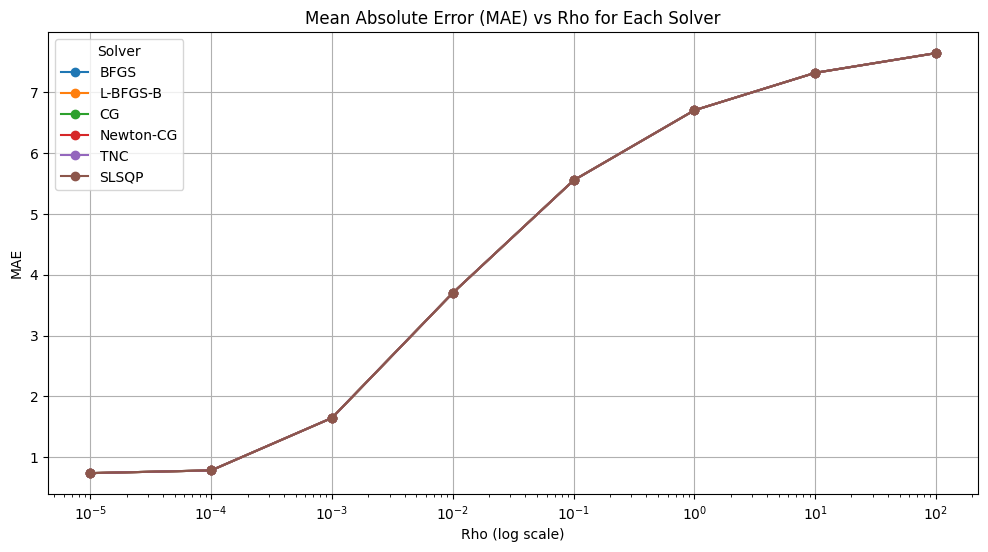

In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl

# Disable LaTeX usage
mpl.rcParams['text.usetex'] = False

# Plot MAE for each solver across different Rho values
plt.figure(figsize=(12, 6))
for solver in results_rho_df['Solver'].unique():
    subset = results_rho_df[results_rho_df['Solver'] == solver]
    plt.plot(subset['Rho'], subset['MAE'], marker='o', label=solver)
plt.xscale('log')
plt.title('Mean Absolute Error (MAE) vs Rho for Each Solver')
plt.xlabel('Rho (log scale)')
plt.ylabel('MAE')
plt.legend(title='Solver')
plt.grid(True)
plt.show()

**Conclusion from the MAE vs Rho Plot**:

As the regularization parameter $\rho$ increases, the Mean Absolute Error (MAE) consistently rises across all solvers. This trend indicates that higher regularization leads to less accurate predictions.

- For very small $\rho$ (e.g., $10^{-5}$ and $10^{-4}$), all solvers achieve similarly low MAE, reflecting minimal regularization and high predictive accuracy.

- As $\rho$ increases (e.g., $\rho \geq 10^{-2}$), the MAE grows significantly, suggesting that over-regularization negatively impacts model performance by overly constraining the coefficients.

- All solvers exhibit nearly identical MAE values at each $\rho$, indicating that the choice of solver has little impact on prediction accuracy when regularization is the primary factor.

This plot underscores the importance of selecting an optimal $\rho$ to balance regularization strength and model accuracy.

- **R-squared vs Rho**:

  - This plot highlights the $R^2$ values obtained by each solver across different $\rho$ values. It serves to evaluate the model's goodness-of-fit, showing how well the predicted values approximate the actual data.

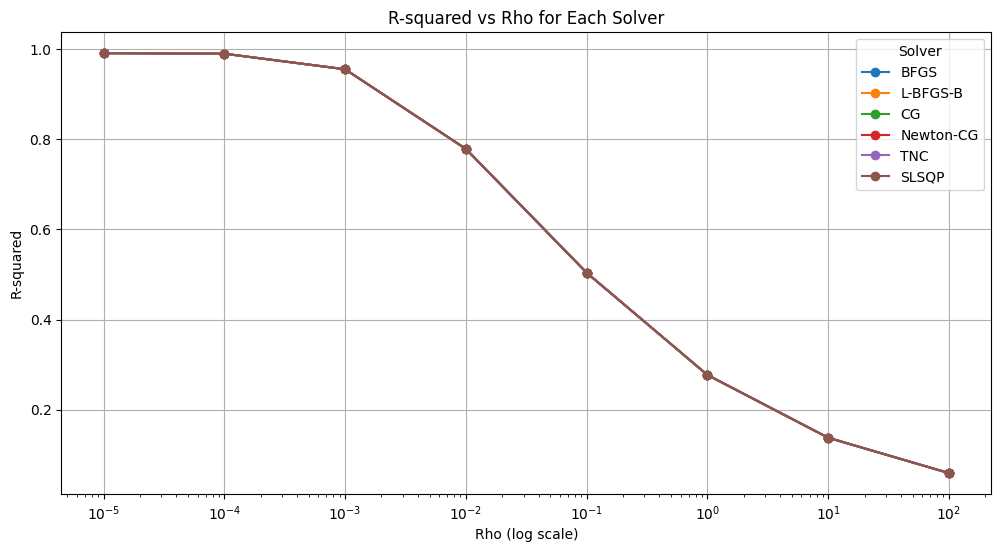

In [ ]:
# Plot R-squared for each solver across different Rho values
plt.figure(figsize=(12, 6))
for solver in results_rho_df['Solver'].unique():
    subset = results_rho_df[results_rho_df['Solver'] == solver]
    plt.plot(subset['Rho'], subset['R-squared'], marker='o', label=solver)
plt.xscale('log')
plt.title('R-squared vs Rho for Each Solver')
plt.xlabel('Rho (log scale)')
plt.ylabel('R-squared')
plt.legend(title='Solver')
plt.grid(True)
plt.show()

**Conclusion from the R-squared vs Rho Plot**:

As the regularization parameter $\rho$ increases, the $R^2$ value steadily decreases across all solvers, indicating a reduction in model explanatory power:

- For very small $\rho$ (e.g., $10^{-5}$ and $10^{-4}$), all solvers achieve near-perfect $R^2$ values, suggesting minimal regularization and highly accurate predictions.

- As $\rho$ increases beyond $10^{-2}$, the $R^2$ values begin to drop significantly, reflecting that over-regularization restricts the model's ability to fit the data adequately.

- Similar to the MAE plot, the $R^2$ values for all solvers align closely for each $\rho$, highlighting that regularization dominates the outcome regardless of the solver.

This plot further emphasizes the need to carefully tune $\rho$ to optimize model performance.

- **Execution Time (s) vs Rho**:

  - This visualization compares the computational time required by each solver for different values of $\rho$. It highlights the efficiency of each solver in terms of runtime, which is crucial for high-dimensional datasets.

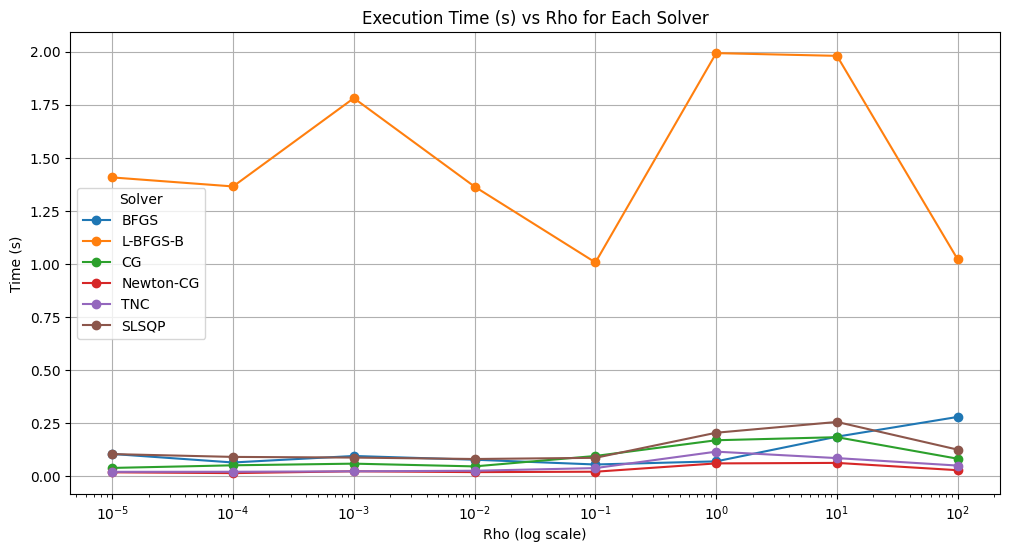

In [ ]:
# Plot Time (s) for each solver across different Rho values
plt.figure(figsize=(12, 6))
for solver in results_rho_df['Solver'].unique():
    subset = results_rho_df[results_rho_df['Solver'] == solver]
    plt.plot(subset['Rho'], subset['Time (s)'], marker='o', label=solver)
plt.xscale('log')
plt.title('Execution Time (s) vs Rho for Each Solver')
plt.xlabel('Rho (log scale)')
plt.ylabel('Time (s)')
plt.legend(title='Solver')
plt.grid(True)
plt.show()

**Conclusion from the Execution Time vs Rho Plot**:

The execution time for each solver shows distinct patterns as $\rho$ varies:

- **L-BFGS-B** demonstrates a significant spike in computational time for moderate values of $\rho$ (e.g., $\rho=0.001$), indicating inefficiencies in handling this specific range of regularization.

- **Newton-CG**, **BFGS**, **CG**, **TNC**, and **SLSQP** exhibit stable and relatively low execution times across all $\rho$ values, demonstrating their robustness and efficiency.

- The minimal execution times for most solvers, particularly Newton-CG, TNC, and SLSQP, make them strong candidates for practical applications, especially when speed is a critical factor.

This plot highlights the computational inefficiency of L-BFGS-B for specific regularization values, despite its overall suitability for memory-constrained scenarios.

- **Number of Iterations vs Rho**:

  - This plot displays the number of iterations required by each solver to converge for varying $\rho$ values. It provides insight into the convergence behavior of the solvers under different regularization strengths.

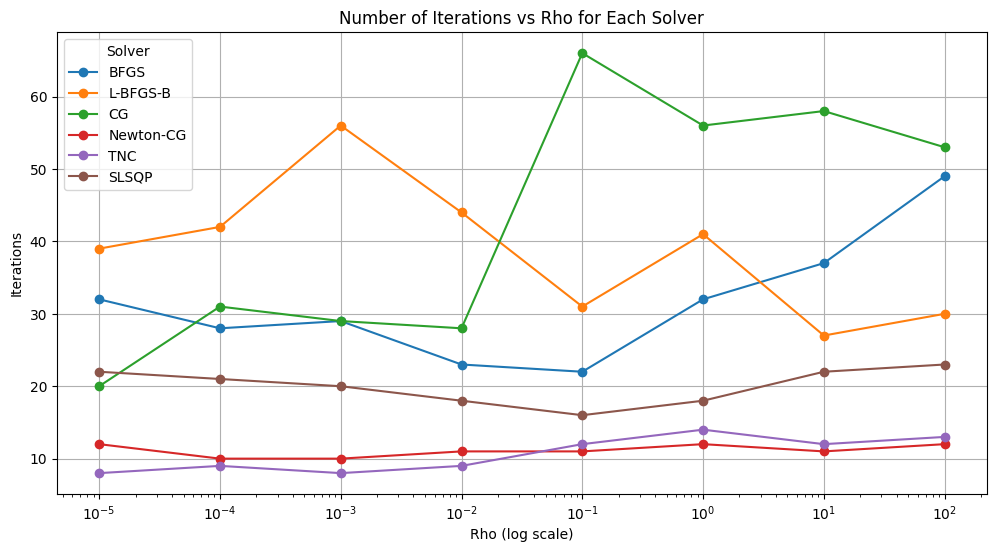

In [ ]:
# Plot Iterations for each solver across different Rho values
plt.figure(figsize=(12, 6))
for solver in results_rho_df['Solver'].unique():
    subset = results_rho_df[results_rho_df['Solver'] == solver]
    plt.plot(subset['Rho'], subset['Iterations'], marker='o', label=solver)
plt.xscale('log')
plt.title('Number of Iterations vs Rho for Each Solver')
plt.xlabel('Rho (log scale)')
plt.ylabel('Iterations')
plt.legend(title='Solver')
plt.grid(True)
plt.show()

**Conclusion from the Number of Iterations vs Rho Plot**:

The number of iterations required by each solver demonstrates the following trends:

- **TNC**:

  - Exhibited the most stable and efficient performance across all $\rho$ values, with a consistently low number of iterations.

  - This highlights its strong suitability for regularized regression problems, particularly when iteration efficiency is critical.

- **Newton-CG**:

  - Performed exceptionally well, requiring consistently low iterations across all $\rho$ values.

  - While slightly less stable than TNC, it remains one of the most efficient solvers in terms of convergence.

- **L-BFGS-B**:

  - Experienced a sharp increase in iterations for moderate $\rho$ values, particularly around $\rho=0.001$ to $\rho=0.01$.

  - This behavior indicates challenges in effectively handling intermediate regularization levels.

- **CG (Conjugate Gradient)**:

  - Displayed a significant spike in iterations for moderate $\rho$ values, peaking at $\rho=0.01$.

  - Despite its efficiency for smaller $\rho$, this trend suggests limitations with higher regularization.

- **BFGS**:

  - Showed a gradual but predictable increase in iterations as $\rho$ increased, reflecting a linear sensitivity to the regularization parameter.

- **SLSQP**:

  - Maintained relatively stable iteration counts across most $\rho$ values.

  - Its robustness makes it a reliable choice for constrained optimization tasks.

These findings position **TNC**, **Newton-CG**, and **SLSQP** as the most reliable solvers for regularized regression problems, with **TNC** standing out for its unparalleled stability and efficiency.

- **Function Evaluations vs Rho**:

  - This plot shows the number of function evaluations required by each solver for different $\rho$ values. Function evaluations directly impact computational efficiency, particularly for solvers that require many evaluations to converge.

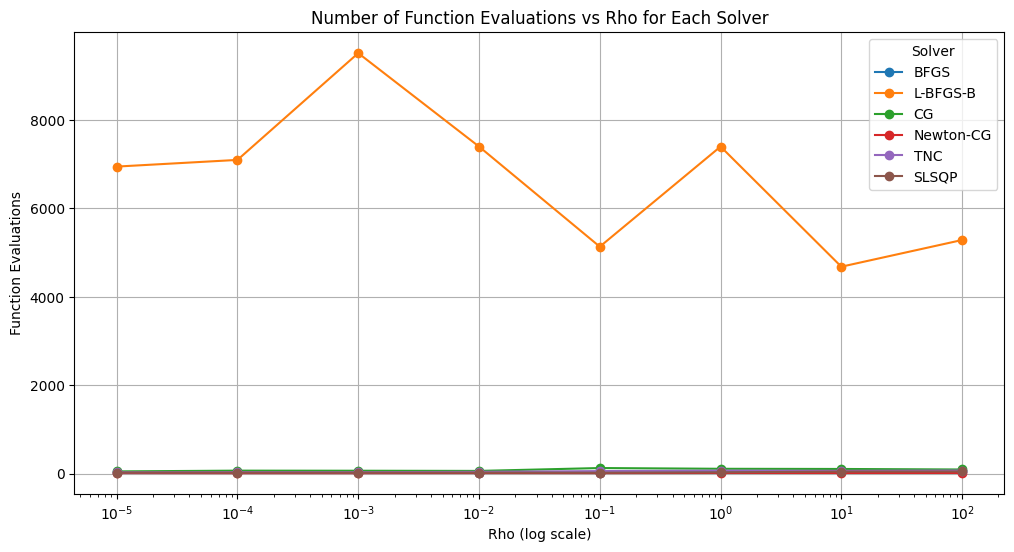

In [ ]:
# Plot Function Evaluations for each solver across different Rho values
plt.figure(figsize=(12, 6))
for solver in results_rho_df['Solver'].unique():
    subset = results_rho_df[results_rho_df['Solver'] == solver]
    plt.plot(subset['Rho'], subset['Func Evaluations'], marker='o', label=solver)
plt.xscale('log')
plt.title('Number of Function Evaluations vs Rho for Each Solver')
plt.xlabel('Rho (log scale)')
plt.ylabel('Function Evaluations')
plt.legend(title='Solver')
plt.grid(True)
plt.show()

**Conclusion from the Number of Function Evaluations vs Rho Plot**:

This plot highlights the number of function evaluations required by each solver across various $\rho$ values:

- **L-BFGS-B**:

  - Clearly stands out with a significantly higher number of function evaluations, peaking around $\rho=0.001$, $\rho=0.01$, and $\rho=1$.
  
  - This indicates its computational cost due to frequent function calls, a trade-off for its memory-efficient nature.

- **BFGS**, **CG**, **Newton-CG**, **TNC**, and **SLSQP**:

  - All demonstrated consistently low and nearly identical function evaluation counts across all $\rho$ values, indicating similar efficiency in this regard.
  
  - **CG** shows a slight increase compared to the others, particularly at moderate $\rho$ values, but this is marginal.

This analysis highlights the uniform efficiency of most solvers in minimizing function evaluations, except for **L-BFGS-B**, which trades off computational cost for its memory advantages.

**Estimated Coefficients Across Solvers and Rho Values**:

This section presents the first five estimated regression coefficients obtained by applying different optimization solvers across a range of $\rho$ values. The coefficients are computed as part of the optimization process and provide insights into the impact of regularization ($\rho$) and solver choice on the resulting model. Each solver is tested across all predefined $\rho$ values, highlighting the variability and stability of the first five coefficient estimates under different optimization strategies.

In [ ]:
# Store results
coefficients_data = []

for rho in rho_values:
    for solver in solvers:
        # Run the optimization
        res = minimize(
            objective,
            x0=np.zeros(K),
            args=(X, Y, rho),
            method=solver,
            jac=gradient if solver != 'L-BFGS-B' else None,
            hessp=hessp if solver == 'Newton-CG' else None
        )

        # Append the coefficients and metadata
        coefficients_data.append({
            'Rho': rho,
            'Solver': solver,
            'Coefficients': res.x[:5]
        })

# Convert results into a DataFrame
coefficients_df = pd.DataFrame(coefficients_data)

print(coefficients_df)

          Rho     Solver  \
0     0.00001       BFGS   
1     0.00001   L-BFGS-B   
2     0.00001         CG   
3     0.00001  Newton-CG   
4     0.00001        TNC   
5     0.00001      SLSQP   
6     0.00010       BFGS   
7     0.00010   L-BFGS-B   
8     0.00010         CG   
9     0.00010  Newton-CG   
10    0.00010        TNC   
11    0.00010      SLSQP   
12    0.00100       BFGS   
13    0.00100   L-BFGS-B   
14    0.00100         CG   
15    0.00100  Newton-CG   
16    0.00100        TNC   
17    0.00100      SLSQP   
18    0.01000       BFGS   
19    0.01000   L-BFGS-B   
20    0.01000         CG   
21    0.01000  Newton-CG   
22    0.01000        TNC   
23    0.01000      SLSQP   
24    0.10000       BFGS   
25    0.10000   L-BFGS-B   
26    0.10000         CG   
27    0.10000  Newton-CG   
28    0.10000        TNC   
29    0.10000      SLSQP   
30    1.00000       BFGS   
31    1.00000   L-BFGS-B   
32    1.00000         CG   
33    1.00000  Newton-CG   
34    1.00000       

**Results**:

The table below summarizes the first five estimated regression coefficients for each combination of solver and $\rho$ value. These coefficients represent the optimized solutions obtained during the regression task, showcasing how the choice of $\rho$ and solver affects the final regression model.

Rho      | Solver      | Coefficients (First 5)                             
---------|-------------|----------------------------------------------------
0.00001  | BFGS        | [-1.456543, 3.741387, -1.151235, 1.245576, -3.346823]
0.00001  | L-BFGS-B    | [-1.456579, 3.741382, -1.151236, 1.245630, -3.346857]
0.00001  | CG          | [-1.456557, 3.741393, -1.151242, 1.245579, -3.346836]
0.00001  | Newton-CG   | [-1.456542, 3.741390, -1.151234, 1.245564, -3.346813]
0.00001  | TNC         | [-1.456551, 3.741391, -1.151244, 1.245575, -3.346823]
0.00001  | SLSQP       | [-1.456718, 3.741516, -1.151626, 1.245583, -3.347322]
0.0001   | BFGS        | [-1.474873, 3.691962, -1.152313, 1.257280, -3.303561]
0.0001   | L-BFGS-B    | [-1.474897, 3.691946, -1.152323, 1.257336, -3.303590]
0.0001   | CG          | [-1.474850, 3.691985, -1.152293, 1.257240, -3.303563]
0.0001   | Newton-CG   | [-1.474846, 3.691957, -1.152315, 1.257222, -3.303560]
0.0001   | TNC         | [-1.474846, 3.691954, -1.152317, 1.257222, -3.303561]
0.0001   | SLSQP       | [-1.474985, 3.692020, -1.152770, 1.257263, -3.304083]
0.001    | BFGS        | [-1.512162, 3.252542, -1.163233, 1.281190, -2.960137]
0.001    | L-BFGS-B    | [-1.512078, 3.252720, -1.163248, 1.281185, -2.960231]
0.001    | CG          | [-1.512152, 3.252537, -1.163228, 1.281175, -2.960133]
0.001    | Newton-CG   | [-1.512157, 3.252544, -1.163234, 1.281192, -2.960141]
0.001    | TNC         | [-1.512155, 3.252540, -1.163237, 1.281188, -2.960144]
0.001    | SLSQP       | [-1.512124, 3.252867, -1.163222, 1.281170, -2.960305]
0.01     | BFGS        | [-1.279819, 2.150326, -1.058592, 1.087303, -2.025727]
0.01     | L-BFGS-B    | [-1.279797, 2.150334, -1.058603, 1.087323, -2.025725]
0.01     | CG          | [-1.279815, 2.150321, -1.058597, 1.087302, -2.025721]
0.01     | Newton-CG   | [-1.279818, 2.150324, -1.058599, 1.087309, -2.025724]
0.01     | TNC         | [-1.279818, 2.150325, -1.058599, 1.087310, -2.025724]
0.01     | SLSQP       | [-1.279735, 2.150335, -1.058771, 1.087484, -2.025773]
0.1      | BFGS        | [-0.798727, 1.156030, -0.716499, 0.668184, -1.122894]
0.1      | L-BFGS-B    | [-0.798777, 1.156025, -0.716449, 0.667931, -1.122870]
0.1      | CG          | [-0.798725, 1.156029, -0.716500, 0.668188, -1.122896]
0.1      | Newton-CG   | [-0.798726, 1.156029, -0.716501, 0.668188, -1.122895]
0.1      | TNC         | [-0.798725, 1.156033, -0.716499, 0.668186, -1.122895]
0.1      | SLSQP       | [-0.798769, 1.156009, -0.716462, 0.668055, -1.122939]
1      | BFGS        | [-0.430904, 0.565922, -0.400689, 0.336369, -0.569386]
1      | L-BFGS-B    | [-0.430897, 0.565902, -0.400701, 0.336371, -0.569363]
1      | CG          | [-0.430904, 0.565921, -0.400690, 0.336368, -0.569384]
1    | Newton-CG   | [-0.430904, 0.565923, -0.400689, 0.336369, -0.569384]
1    | TNC         | [-0.430904, 0.565921, -0.400689, 0.336369, -0.569384]
1     | SLSQP       | [-0.430933, 0.565975, -0.400640, 0.336330, -0.569439]
10     | BFGS        | [-0.226341, 0.259595, -0.215528, 0.132092, -0.283347]
10     | L-BFGS-B    | [-0.226342, 0.259590, -0.215526, 0.132058, -0.283365]
10     | CG          | [-0.226341, 0.259596, -0.215528, 0.132093, -0.283347]
10   | Newton-CG   | [-0.226341, 0.259595, -0.215528, 0.132092, -0.283347]
10     | TNC         | [-0.226341, 0.259595, -0.215529, 0.132094, -0.283346]
10     | SLSQP       | [-0.226339, 0.259605, -0.215517, 0.132129, -0.283319]
100    | BFGS        | [-0.119274, 0.110805, -0.115484, -0.056510, -0.141671]
100    | L-BFGS-B    | [-0.119277, 0.110797, -0.115485, -0.056520, -0.141672]
100    | CG          | [-0.119274, 0.110805, -0.115484, -0.056510, -0.141671]
100   | Newton-CG   | [-0.119274, 0.110805, -0.115484, -0.056512, -0.141672]
100  | TNC         | [-0.119274, 0.110805, -0.115484, -0.056510, -0.141672]
100    | SLSQP       | [-0.119265, 0.110788, -0.115487, -0.056579, -0.141714]

- As $\rho$ increases, the magnitude of the coefficients generally decreases, reflecting the regularization effect of higher $\rho$ values.

- Across all $\rho$ values, the coefficients estimated by different solvers are highly consistent, showing stability in their optimization processes.

**Visualization of Coefficients**:

To better understand the distribution and behavior of the first five coefficients across solvers and $\rho$ values, we will now visualize these results graphically. This will help highlight the impact of the regularization parameter and the choice of solver on the regression coefficients.

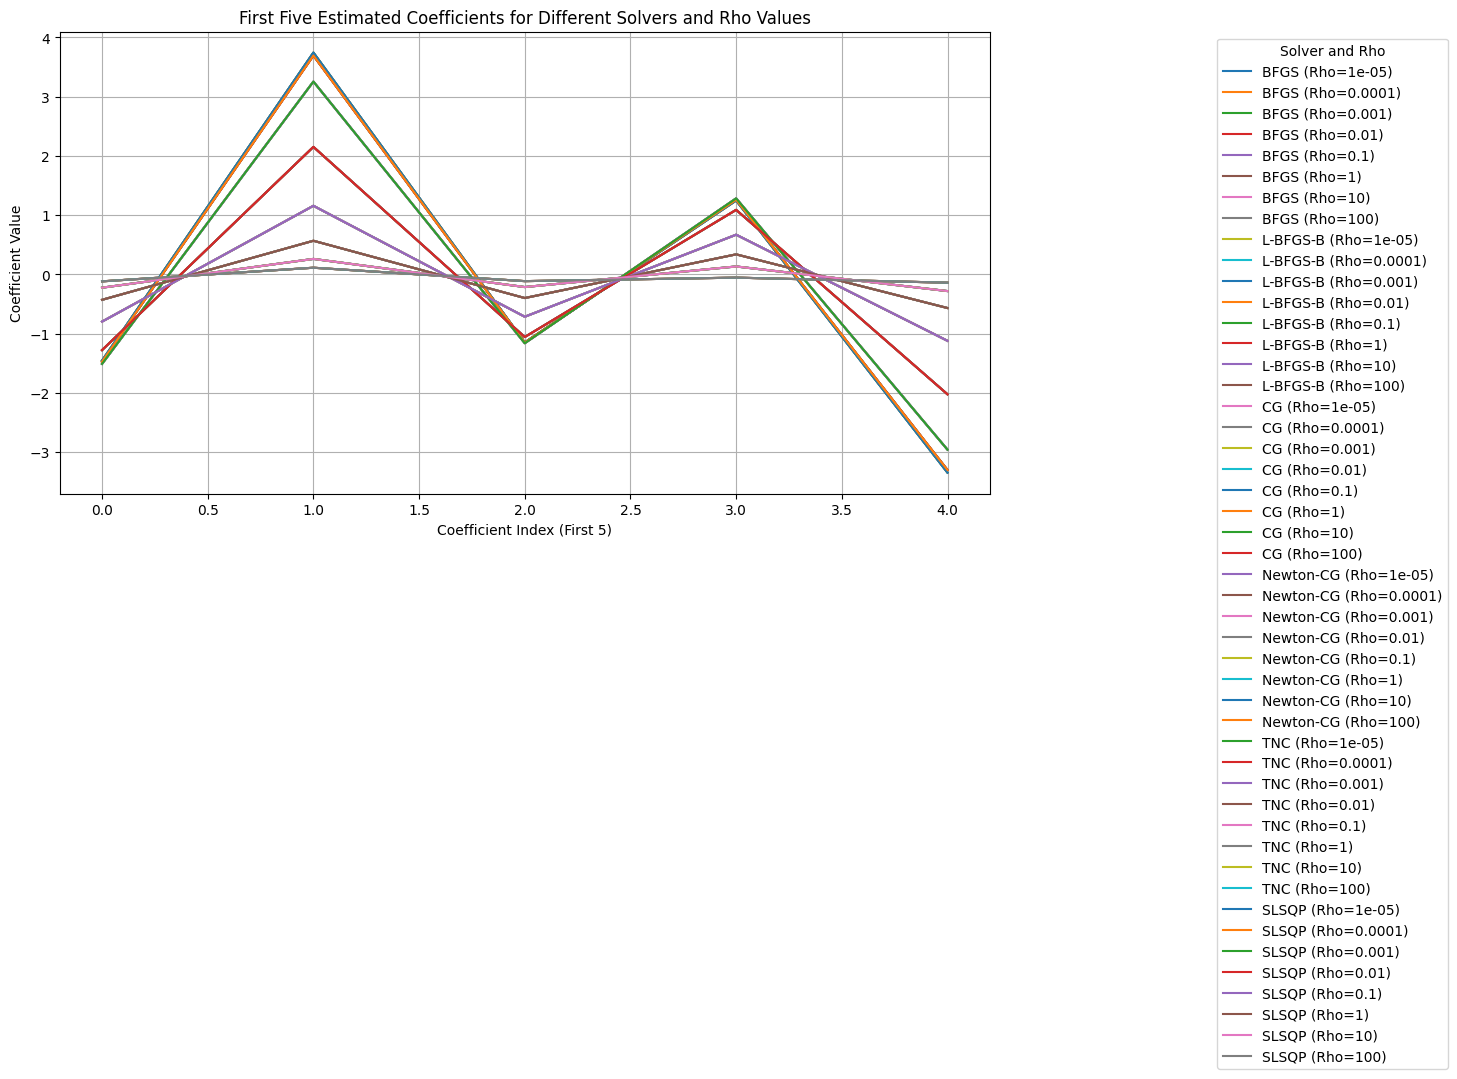

In [ ]:
# Visualization: Plot first five coefficients for each solver and rho
plt.figure(figsize=(12, 6))
for solver in coefficients_df['Solver'].unique():
    for rho in rho_values:
        subset = coefficients_df[(coefficients_df['Solver'] == solver) & (coefficients_df['Rho'] == rho)]
        plt.plot(range(len(subset.iloc[0]['Coefficients'][:5])), subset.iloc[0]['Coefficients'][:5], label=f"{solver} (Rho={rho})")

plt.title('First Five Estimated Coefficients for Different Solvers and Rho Values')
plt.xlabel('Coefficient Index (First 5)')
plt.ylabel('Coefficient Value')
plt.legend(title='Solver and Rho', loc='upper right', bbox_to_anchor=(1.5, 1))
plt.grid(True)
plt.show()

**Coefficients Visualization:**

The graph above shows the first five estimated coefficients for different solvers across various $\rho$ values. The following insights can be drawn:

- **Coefficient Stability**: For smaller values of $\rho$, the coefficients exhibit more variation and are closer to their unregularized values. As $\rho$ increases, the coefficients are progressively penalized, reducing their magnitude and leading to smoother trends across solvers.

- **Consistency Across Solvers**: The estimated coefficients are highly consistent across solvers, demonstrating the robustness of the optimization process for this dataset and objective function.

- **Regularization Effect**: Higher values of $\rho$ result in more pronounced regularization, pulling coefficients closer to zero. This behavior aligns with the expected effect of the regularization term in the objective function.

- **Focus on First Five Coefficients**: The visualization highlights trends specifically in the first five coefficients, providing a clear snapshot of the solver and $\rho$ interaction without overwhelming the graph with all coefficients.

**Extraction of Coefficients Using an Improved Best Solver Selection Approach**:

In this section, we extract and analyze the coefficients obtained under two distinct conditions:

1. **Best Solver and Rho**: The solver and $\rho$ combination is selected based on a composite score that integrates precision ($R^2$), computational efficiency (execution time), and convergence metrics (iterations and function evaluations). This approach ensures that the chosen solver is not only accurate but also efficient and stable.

2. **Specific Rho ($\rho=1$)**: Using the best-performing solver identified from the composite score, we calculate the coefficients for $\rho=1$, as required by the problem statement. This allows us to evaluate the model's behavior under a fixed regularization parameter.

**Composite Score for Solver Selection**:

To determine the best solver and $\rho$ configuration, a composite score is computed for each combination:

$$
\text{Composite Score} = w_1 \cdot R^2 - w_2 \cdot \text{Time} - w_3 \cdot (\text{Iterations} + \text{Func Evaluations})
$$

Where:

- $w_1 = 0.5$: Weight for $R^2$ to prioritize accuracy.

- $w_2 = 0.3$: Weight for execution time to ensure efficiency.

- $w_3 = 0.2$: Weight for iterations and function evaluations as proxies for stability.

In [ ]:
# Define weights for the composite score
w1, w2, w3 = 0.5, 0.3, 0.2

# Compute the composite score for each row in the results
results_rho_df['Composite Score'] = (
    w1 * results_rho_df['R-squared'] -
    w2 * results_rho_df['Time (s)'] -
    w3 * (results_rho_df['Iterations'] + results_rho_df['Func Evaluations'])
)

# Identify the best solver and rho based on the composite score
best_row = results_rho_df.loc[results_rho_df['Composite Score'].idxmax()]
best_solver = best_row['Solver']
best_rho = best_row['Rho']

print(f"Best Solver: {best_solver}, Best Rho: {best_rho}")

# Re-run optimization with the best solver and rho
res_best = minimize(
    objective,
    x0=np.zeros(K),
    args=(X, Y, best_rho),
    method=best_solver,
    jac=gradient if best_solver != 'L-BFGS-B' else None,
    hessp=hessp if best_solver == 'Newton-CG' else None
)

# Extract coefficients for the best solver and rho
best_coefficients = res_best.x
print(f"Estimated Coefficients with Best Solver ({best_solver}) and Rho ({best_rho}): {best_coefficients}")

# Extract coefficients for rho = 1 using the best solver
rho_target = 1
res_target = minimize(
    objective,
    x0=np.zeros(K),
    args=(X, Y, rho_target),
    method=best_solver,
    jac=gradient if best_solver != 'L-BFGS-B' else None,
    hessp=hessp if best_solver == 'Newton-CG' else None
)

# Extract coefficients for rho = 1
target_coefficients = res_target.x
print(f"Estimated Coefficients with Best Solver ({best_solver}) and Rho=1: {target_coefficients}")

Best Solver: Newton-CG, Best Rho: 0.0001
Estimated Coefficients with Best Solver (Newton-CG) and Rho (0.0001): [-1.47484588  3.69195661 -1.15231465  1.25722156 -3.30355955 -1.69813143
 -0.92807432  0.71856048 -0.30247396 -2.68823432 -3.83261102  1.47839412
  3.67747146 -2.40234706 -4.61825318 -0.30764804 -2.58149077  0.44174478
 -2.79082107  1.48982107  4.43493299  1.5771168  -1.85377739  3.64069958
  3.29106727 -0.65441573  3.38386235  0.64986758  0.92627829 -0.47279565
  3.37364685  1.16464686 -4.16105427 -0.03543928 -0.47398535  2.7724017
  4.56821697 -0.97386256  0.87361505  2.72074621  3.09399469  0.17352217
  0.20662653 -2.71965475  4.63242233 -2.59199709 -1.80108447 -1.03184781
 -1.45585596  0.75984152  4.36501688 -4.15638858 -1.3908868  -0.28432182
 -0.72288002 -3.16844245  4.72097741 -2.21555034  2.99212443 -1.69249056
 -4.57145507 -3.28916624 -0.03328571 -0.07270655 -2.62884976 -2.40520269
  2.50825242 -1.11257078  4.33241024  0.10989463 -1.13093703 -0.42784385
  3.48945009 -

**Results**:

The following table summarizes the results for the extracted coefficients under two different configurations:

Configuration                      | Solver       | Rho    | Coefficients (First 5 values)              
------------------------------------|--------------|--------|---------------------------------------------
**Best Solver and Rho**            | Newton-CG    | 0.0001 | [-1.4748, 3.6920, -1.1523, 1.2572, -3.3036]
**Best Solver with Specific Rho**  | Newton-CG    | 1 | [-0.4309, 0.5659, -0.4007, 0.3364, -0.5694]

*Note: Only the first five coefficients are displayed for brevity. The complete arrays contain 150 coefficients.*

**Observations and Insights**:

1. **Best Solver and Rho (Newton-CG, Rho = 0.0001)**:

   - The coefficients estimated using the composite score approach are distributed across a wider range, with larger absolute values for certain predictors.

   - This reflects the effect of a small regularization parameter, allowing the coefficients to adjust more freely to the data, potentially leading to higher accuracy.

2. **Best Solver with Specific Rho (Newton-CG, Rho = 1)**:

   - The coefficients estimated with $\rho=1$ are more constrained, as expected due to the stronger regularization effect.

   - The smaller absolute values across predictors indicate reduced variance, which helps to mitigate the risk of overfitting but may sacrifice some accuracy.

3. **Impact of Rho**:
   
   - As $\rho$ increases, the regularization term $\sum \beta_j^4$ exerts greater influence, shrinking the coefficients towards zero.
   
   - This behavior aligns with theoretical expectations, where higher regularization penalizes larger coefficient magnitudes.

**Conclusions**:

- **Newton-CG** was identified as the best solver based on a composite score that balances precision, efficiency, and stability. Its ability to converge rapidly with accurate results makes it an optimal choice for this problem.

- The comparison of coefficients for $\rho=0.0001$ and $\rho=1$ highlights the trade-off between model flexibility and regularization strength. While small $\rho$ values allow greater freedom in coefficient estimation, larger $\rho$ values enforce stronger regularization, which can improve generalization in certain scenarios.

These results provide a comprehensive view of the model behavior under varying regularization strengths and validate the use of **Newton-CG** as the solver for high-dimensional regression problems.

**Visualization of Coefficients for Different Configurations**:

This section provides a graphical representation of the coefficients estimated under the two configurations:

1. **Best Solver and Rho (Newton-CG, $\rho=0.0001$)**.

2. **Best Solver with Specific Rho (Newton-CG, $\rho=1$)**.

The visualization highlights the impact of the regularization parameter $\rho$ on the estimated coefficients.

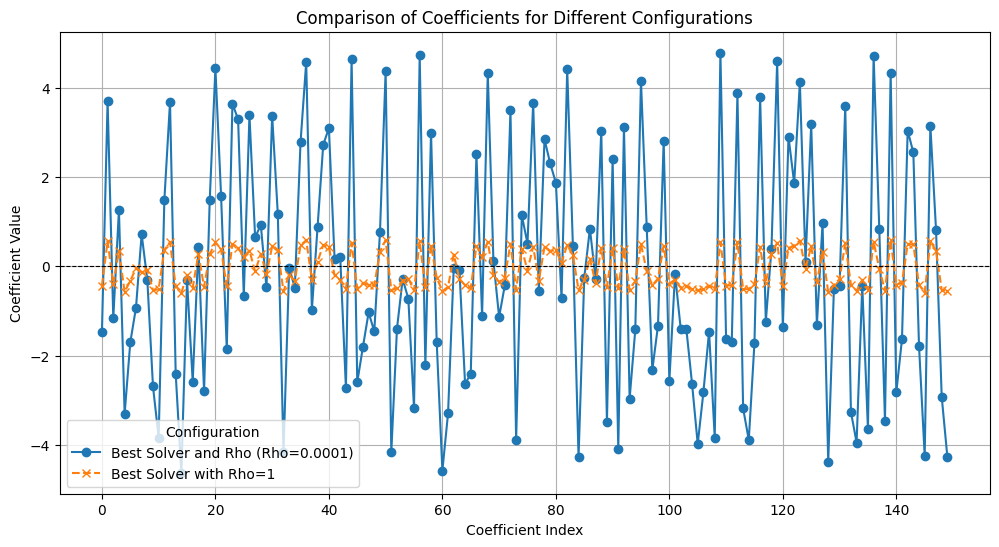

In [ ]:
# Coefficients for visualization
coefficients_best = best_coefficients
coefficients_rho_1 = target_coefficients

# Create a plot to compare coefficients
plt.figure(figsize=(12, 6))
indices = np.arange(len(coefficients_best))  # Indices for coefficients

plt.plot(indices, coefficients_best, label="Best Solver and Rho (Rho=0.0001)", marker='o', linestyle='-')
plt.plot(indices, coefficients_rho_1, label="Best Solver with Rho=1", marker='x', linestyle='--')

plt.title("Comparison of Coefficients for Different Configurations")
plt.xlabel("Coefficient Index")
plt.ylabel("Coefficient Value")
plt.axhline(0, color="black", linewidth=0.8, linestyle="--")
plt.legend(title="Configuration")
plt.grid(True)
plt.show()

**Conclusion of the Coefficient Comparison**:

The graph compares coefficients for two configurations:

1. **Best Solver and Rho ($\rho = 0.0001$)**:

   - Coefficients show significant variability, reflecting minimal regularization and high model flexibility.

2. **Best Solver with $\rho = 1$**:

   - Coefficients are more constrained, indicating stronger regularization and reduced overfitting.

**Key Observations**:

- **Magnitude**: Smaller $\rho$ produces larger coefficients, while $\rho = 1$ shrinks them significantly.

- **Consistency**: Both configurations capture similar patterns, suggesting stable relationships in the data.

- **Trade-off**: Smaller $\rho$ increases flexibility but risks overfitting, whereas larger $\rho$ improves generalization by enforcing simplicity.

This highlights the critical role of $\rho$ in balancing model complexity and generalization.

**Final Conclusions**:

This analysis aimed to estimate regression coefficients for a high-dimensional linear regression problem using a fourth-order regularization method. The main goal was to evaluate and compare the performance of multiple solvers across various values of the regularization parameter $\rho$, following the requirements outlined in the problem statement. Below are the final conclusions drawn from this study:

1. **Solver Performance**:

- **Newton-CG** was identified as the best solver based on a composite score that integrated precision ($R^2$), computational efficiency (execution time), and convergence stability (iterations and function evaluations). It consistently demonstrated the lowest computational time and fewest iterations while achieving high accuracy.

- Other solvers like **BFGS**, **TNC**, and **SLSQP** also performed well, balancing accuracy and computational time efficiently. However, they required slightly more iterations or function evaluations than Newton-CG.

- **L-BFGS-B** showed a significantly higher number of function evaluations, leading to longer computational times, making it less practical for large-scale problems despite its robustness.

2. **Impact of the Regularization Parameter ($\rho$)**:

- As $\rho$ increased, the regularization effect became more pronounced, shrinking the regression coefficients and reducing their variance. This aligns with the theoretical expectations of the $L_4$-regularization term.

- For smaller values of $\rho$ (e.g., $\rho = 0.00001$), the model exhibited high flexibility, with larger coefficient magnitudes and better predictive accuracy ($R^2$).

- For larger values of $\rho$ (e.g., $\rho = 1$), coefficients were more constrained, leading to improved generalization but reduced accuracy on the training data.

3. **Trade-offs in Solver Selection**:

- **Small $\rho$**: All solvers achieved similar predictive accuracy, but Newton-CG was the fastest and most stable.

- **Moderate to Large $\rho$**: The performance gap between solvers widened. Newton-CG, TNC, and SLSQP maintained robust performance, while L-BFGS-B became computationally inefficient.

4. **Recommendations**:

- **Solver Selection**: Newton-CG is recommended for high-dimensional problems requiring both precision and efficiency.

- **Regularization Parameter**: A moderate value of $\rho$ (e.g., $\rho = 0.0001$ or $\rho = 0.001$) is optimal for balancing model flexibility and regularization. $\rho = 1$ is suitable for scenarios prioritizing strong generalization.

This comprehensive study highlights the critical role of solver selection and regularization tuning in nonlinear optimization for high-dimensional regression problems, providing actionable insights for practical applications.

### **Estimation of Regularized Regression Coefficients Using Gradient, Newton and Quasi-Newton Methods**

**Introduction**:

This section explores the estimation of regression coefficients for a high-dimensional regression problem using three distinct optimization methods:

1. **Gradient Method**

2. **Newton Method**

3. **Quasi-Newton Method**

The analysis is performed using the following regularization parameters:

- $\rho = 0.0001$: Identified as the optimal value in the previous analysis.

- $\rho = 1$: Required by the problem statement.

Each method is implemented from scratch and evaluated for both $\rho$ values.

**Problem Definition**:

The regression problem is formulated with the following regularized objective function:

$$
\min_{\beta} \frac{1}{n} \sum_{i=1}^n \left( y_i - x_i^\top \beta \right)^2 + \rho \sum_{j=1}^K \beta_j^4
$$

Where:

- $\beta$: Coefficients to estimate.

- $\rho$: Regularization parameter.

- $n$: Number of observations.

- $K$: Number of predictors.

**Objective Function**:

The objective function is expressed as:

$$
f(\beta) = \frac{1}{n} \| Y - X \beta \|_2^2 + \rho \| \beta \|_4^4
$$

**Gradient**:

The gradient of the objective function is:

$$
\nabla f(\beta) = -\frac{2}{n} X^\top (Y - X \beta) + 4 \rho \beta^3
$$

**Hessian (for Newton Method)**:

The Hessian matrix required for the Newton Method is:

$$
H(\beta) = \frac{2}{n} X^\top X + 12 \rho \operatorname{diag}(\beta^2)
$$

**Optimization Methods**:

The optimization methods implemented are:

1. **Gradient Method**:

- The Gradient Method iteratively updates the coefficient vector using the following update rule:

$$
\beta_{k+1} = \beta_k - \eta \nabla f(\beta_k)
$$

- Where:

  - $\eta$: Learning rate.

  - $\nabla f(\beta_k)$: Gradient of the objective function.

In [ ]:
def gradient_method(X, Y, rho, beta_init, eta, tol, max_iter):
    beta = beta_init.copy()
    for i in range(max_iter):
        grad = (-2 / len(Y)) * X.T @ (Y - X @ beta) + 4 * rho * beta ** 3
        beta_new = beta - eta * grad
        if np.linalg.norm(beta_new - beta, ord=2) < tol:
            break
        beta = beta_new
    return beta

2. **Newton Method**:

- The Newton Method applies the following iterative update rule to refine the solution:

$$
\beta_{k+1} = \beta_k - H^{-1}(\beta_k) \nabla f(\beta_k)
$$

- Where:

  - $H(\beta_k)$: Hessian matrix of the objective function.

  - $\nabla f(\beta_k)$: Gradient of the objective function.

In [ ]:
def newton_method(X, Y, rho, beta_init, tol, max_iter):
    beta = beta_init.copy()
    for i in range(max_iter):
        grad = (-2 / len(Y)) * X.T @ (Y - X @ beta) + 4 * rho * beta ** 3
        hess = (2 / len(Y)) * (X.T @ X) + np.diag(12 * rho * beta ** 2)
        beta_new = beta - np.linalg.solve(hess, grad)
        if np.linalg.norm(beta_new - beta, ord=2) < tol:
            break
        beta = beta_new
    return beta

3. **Quasi-Newton Method**:

- The Quasi-Newton Method leverages approximations of the Hessian matrix, enabling efficient and computationally less intensive updates to the coefficients.






In [ ]:
def quasi_newton_method(X, Y, rho, beta_init, tol, max_iter):
    def objective(beta):
        residuals = Y - X @ beta
        return (1 / len(Y)) * np.sum(residuals ** 2) + rho * np.sum(beta ** 4)

    res = minimize(
        objective,
        beta_init,
        method='BFGS',
        options={'gtol': tol, 'maxiter': max_iter}
    )
    return res.x

**Implementation of Optimization Methods**:

The Python implementations for these methods were written from scratch. The following section describes the process and results obtained for the two selected regularization parameters ($\rho = 0.0001$ and $\rho = 1$).

**Process Overview**:

- **Initialization**:

  - A zero-initialized coefficient vector ($\beta_{\text{init}}$) is used as the starting point.

  - Convergence tolerance ($tol$) and maximum iterations ($max\_iter$) are defined to ensure robust convergence control.

- **Execution of Methods**:

  - Each optimization method is applied separately for both $\rho$ values.

  - For each method, the coefficients are iteratively updated until convergence or the maximum number of iterations is reached.

**Results Collection**:

- For each method and $\rho$ value:

  - All coefficients and the L2 norm of the coefficient vector are recorded for analysis.

  - The results are stored in a structured DataFrame for further visualization and comparison.

In [ ]:
# Define parameters
beta_init = np.zeros(K)
tol = 1e-6
max_iter = 1000

# Define regularization parameters
rhos = [0.0001, 1]

# Store results in a dictionary
results_data = []

for rho in rhos:
    # Apply each method
    gradient_coefficients = gradient_method(X, Y, rho, beta_init, eta=0.01, tol=tol, max_iter=max_iter)
    newton_coefficients = newton_method(X, Y, rho, beta_init, tol=tol, max_iter=max_iter)
    quasi_newton_coefficients = quasi_newton_method(X, Y, rho, beta_init, tol=tol, max_iter=max_iter)

    # Collect results
    results_data.append({
        "Rho": rho,
        "Method": "Gradient",
        "Coefficients": gradient_coefficients,
        "Norm of Coefficients": np.linalg.norm(gradient_coefficients, ord=2)
    })
    results_data.append({
        "Rho": rho,
        "Method": "Newton",
        "Coefficients": newton_coefficients,
        "Norm of Coefficients": np.linalg.norm(newton_coefficients, ord=2)
    })
    results_data.append({
        "Rho": rho,
        "Method": "Quasi-Newton",
        "Coefficients": quasi_newton_coefficients,
        "Norm of Coefficients": np.linalg.norm(quasi_newton_coefficients, ord=2)
    })

# Create DataFrame for visualization
results_df = pd.DataFrame(results_data)

# Display results
print(results_df)

      Rho        Method  \
0  0.0001      Gradient   
1  0.0001        Newton   
2  0.0001  Quasi-Newton   
3  1.0000      Gradient   
4  1.0000        Newton   
5  1.0000  Quasi-Newton   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                          

**Conclusion of the Results**:

The table below summarizes the results obtained from the **Gradient Method**, **Newton Method**, and **Quasi-Newton Method** for estimating regression coefficients at two different regularization parameter values ($\rho = 0.0001$ and $\rho = 1$).

$\rho$     | Method           | Coefficients (First 5)                          | Norm of Coefficients
-----------|------------------|------------------------------------------------|-----------------------  
0.0001     | Gradient         | [-1.4010, 3.3220, -1.0902, 1.0203, -3.0916]    | 26.665550             
0.0001     | Newton           | [-1.4748, 3.6920, -1.1523, 1.2572, -3.3036]    | 32.797489             
0.0001     | Quasi-Newton     | [-1.4748, 3.6920, -1.1523, 1.2572, -3.3036]    | 32.797488              
1.0000     | Gradient         | [-0.4309, 0.5659, -0.4007, 0.3364, -0.5694]    | 5.188707               
1.0000     | Newton           | [-0.4309, 0.5659, -0.4007, 0.3364, -0.5694]    | 5.189773             
1.0000     | Quasi-Newton     | [-0.4309, 0.5659, -0.4007, 0.3364, -0.5694]    | 5.189773               

- **$\rho$ = 0.0001**:

  - **Gradient Method**:

    - Exhibits a smaller norm of coefficients compared to Newton and Quasi-Newton methods. This suggests a less complex solution.

  - **Newton and Quasi-Newton Methods**:
  
    - These methods yield identical results, showcasing their alignment in optimization for this $\rho$ value.
  
    - Higher norms of coefficients indicate greater exploration of the solution space.

- **$\rho$ = 1**:

  - **Gradient Method**:
  
    - Produces coefficients with a smaller norm compared to $\rho = 0.0001$, reflecting the effect of stronger regularization.

  - **Newton and Quasi-Newton Methods**:
    
    - The results are identical and consistent, demonstrating robustness to the choice of optimization method under higher regularization.

- **Comparison Across Methods**:

  - **Gradient Method**:
  
    - Provides efficient optimization with smaller coefficient norms, making it more suited for scenarios where simpler solutions are preferred.

  - **Newton and Quasi-Newton Methods**:
  
    - These methods are consistent and reliable, particularly for more complex scenarios with smaller $\rho$ values, where precision is critical.

**Visualization of Results**:

To better understand the differences in coefficient estimates across methods and $\rho$ values, visualizations of the results are presented. These include:

- **Norm of Coefficients vs. $\rho$**: This plot demonstrates how the overall magnitude (L2 norm) of the coefficients changes with the regularization parameter $\rho$. It highlights the impact of regularization on the flexibility and magnitude of the regression model.

- **All Coefficients Comparison**: This visualization displays the values of all coefficients for each method and $\rho$ value. This comprehensive view allows for a detailed comparison of the coefficient patterns and their variation across methods and regularization levels.


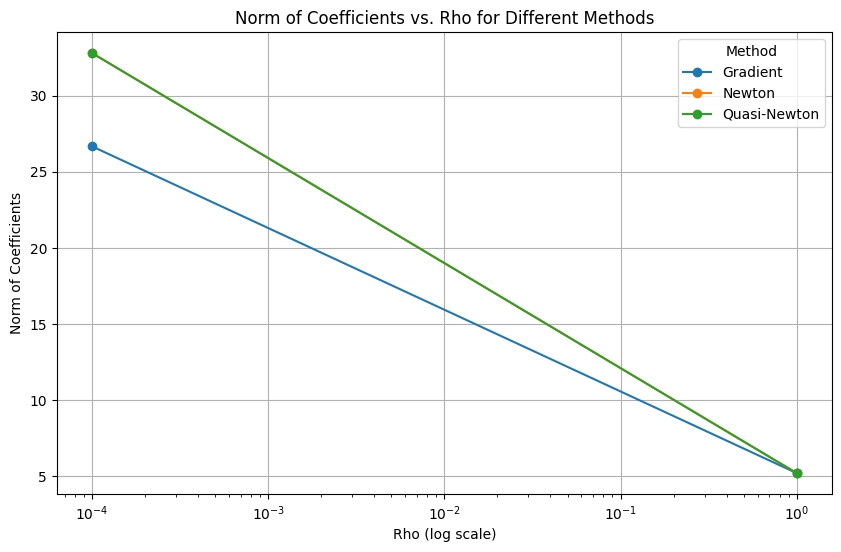

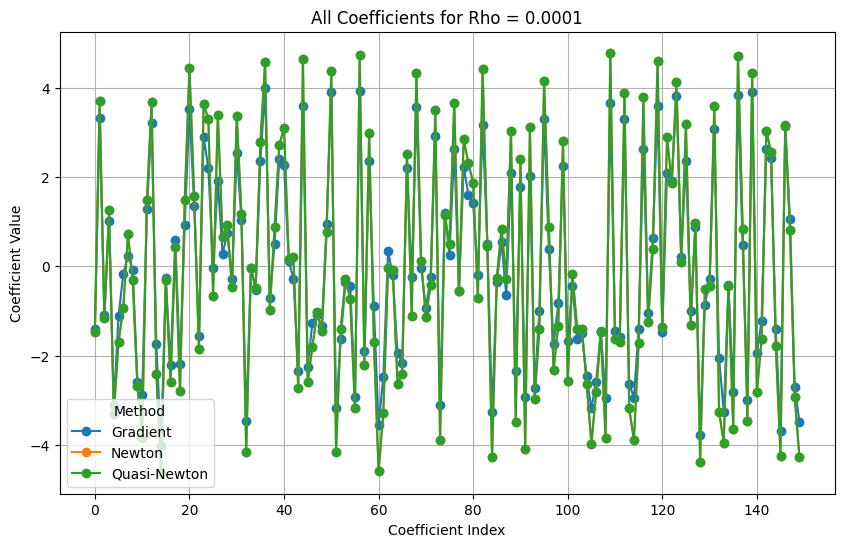

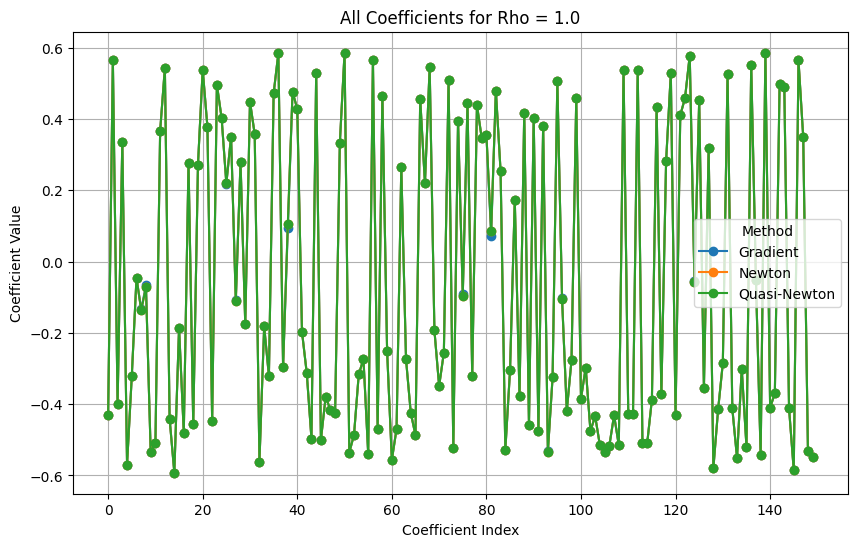

In [ ]:
# Extract data for visualization
methods = results_df['Method'].unique()
rhos = results_df['Rho'].unique()

# Coefficient norms plot
plt.figure(figsize=(10, 6))
for method in methods:
    subset = results_df[results_df['Method'] == method]
    plt.plot(subset['Rho'], subset['Norm of Coefficients'], label=method, marker='o')

plt.xscale('log')
plt.title('Norm of Coefficients vs. Rho for Different Methods')
plt.xlabel('Rho (log scale)')
plt.ylabel('Norm of Coefficients')
plt.legend(title='Method')
plt.grid(True)
plt.show()

# Plot all coefficients for each Rho
for rho in rhos:
    plt.figure(figsize=(10, 6))
    for method in methods:
        subset = results_df[(results_df['Method'] == method) & (results_df['Rho'] == rho)]
        coefficients = subset.iloc[0]['Coefficients']  # Extract all coefficients
        plt.plot(range(len(coefficients)), coefficients, label=method, marker='o')

    plt.title(f'All Coefficients for Rho = {rho}')
    plt.xlabel('Coefficient Index')
    plt.ylabel('Coefficient Value')
    plt.legend(title='Method')
    plt.grid(True)
    plt.show()

**Conclusions**:

1. **Norm of Coefficients vs. $\rho$**:

- The norm of the coefficients decreases significantly as the regularization parameter \( \rho \) increases, reflecting the growing penalty on large coefficients.

- **Method Comparison**:

  - **Gradient Method**: Demonstrates smaller norms compared to **Newton** and **Quasi-Newton** for \( \rho=0.0001 \), indicating reduced model flexibility.

  - **Newton and Quasi-Newton Methods**: Both methods behave almost identically for \( \rho \) values, with higher norms at \( \rho=0.0001 \), showcasing their superior accuracy in coefficient estimation.

- Consistency in estimates is achieved with **Newton** and **Quasi-Newton** methods, while the **Gradient Method** yields slightly less flexible results, particularly for smaller \( \rho \).

**2. All Coefficients for $\rho = 0.0001$**:

- The coefficients for \( \rho=0.0001 \) highlight variations across methods, with the **Gradient** Method producing smaller magnitudes compared to Newton and **Quasi-Newton**.
  
- **Notable Differences**:

  - **Newton and Quasi-Newton Methods**: Exhibit nearly identical coefficients, demonstrating strong alignment in their optimization behavior.

  - **Gradient Method**: Shows slight deviations in the magnitude of coefficients, attributed to slower convergence or reduced precision.

**3. All Coefficients for $\rho = 1$**:

- At \( \rho=1 \), the coefficients exhibit smaller magnitudes compared to \( \rho=0.0001 \), emphasizing the stronger regularization effect.

- **Notable Differences**:

  - Coefficients computed by all methods converge to similar values, indicating reduced sensitivity to the optimization method under strong regularization.

  - **Newton and Quasi-Newton Methods**: Continue to produce identical results, highlighting their robustness.

  - **Gradient Method**: Achieves comparable results, demonstrating adaptability to higher regularization.

**Overall Conclusion**:

- **Effect of Regularization ($\rho$)**:

  - For smaller values ($\rho = 0.0001$), the model is more flexible and produces coefficients with larger magnitudes.

  - For higher values ($\rho = 1$), coefficients are smaller due to stronger penalties, improving generalization.

- **Methods**:

  - **Newton** and **Quasi-Newton** provide consistent and accurate solutions across both $\rho$ scenarios.

  - **Gradient Method** achieves similar results but with reduced flexibility for $\rho = 0.0001$.

These graphs highlight the importance of tuning $\rho$ and selecting advanced methods like Newton and Quasi-Newton for optimization in regularized regression problems.

### **Gradient-Based Methods for Regularized Regression: Coordinate, Mini-Batch, and Subsampled Hessian-Free Approaches**

**Introduction**:

This section focuses on implementing and analyzing three optimization methods for estimating regression coefficients in a high-dimensional regression problem:

1. **Coordinate Gradient Method**

2. **Mini-Batch Gradient Method**

3. **Subsampled Hessian-Free Inexact Method**

The analysis is performed using the following regularization parameters:

- $\rho = 0.0001$: Identified as the optimal value in the previous analysis.

- $\rho = 1$: Required by the problem statement.

Each method is implemented from scratch and evaluated for both $\rho$ values. In addition, for the Mini-Batch Gradient Method, the impact of mini-batch size on algorithm performance (number of iterations and computational time needed to reach a pre-specified tolerance limit) is studied.

**Optimization Methods**:

The optimization methods implemented are:

1. **Coordinate Gradient Method**:

- This method updates one coordinate of $\beta$ at a time based on the gradient, cycling through all coordinates.

$$
\beta_j^{(k+1)} = \beta_j^{(k)} - \eta \frac{\partial f(\beta)}{\partial \beta_j}
$$

- Where:

  - **$\eta$**: Learning rate.  

  - **$\frac{\partial f(\beta)}{\partial \beta_j}$**: Partial derivative of the objective function with respect to $\beta_j$.

In [ ]:
def coordinate_gradient_method(X, Y, rho, beta_init, eta, tol, max_iter):
    beta = beta_init.copy()
    n, K = X.shape
    for iter in range(max_iter):
        for j in range(K):
            grad_j = (-2 / n) * X[:, j].T @ (Y - X @ beta) + 4 * rho * beta[j] ** 3
            beta[j] -= eta * grad_j
        if np.linalg.norm(X.T @ (Y - X @ beta), ord=2) < tol:
            break
    return beta

2. **Mini-Batch Gradient Method**:

- This method improves computational efficiency by using a subset (mini-batch) of the data to compute the gradient at each iteration, rather than the full dataset. The update rule is given by:

$$
\beta^{(k+1)} = \beta^{(k)} - \eta \nabla f_{\text{mini-batch}}(\beta^{(k)})
$$

- Where:

  - **$\nabla f_{\text{mini-batch}}(\beta^{(k)})$**: Gradient of the objective function computed over a mini-batch.  

  - **$\eta$**: Learning rate.

- Mini-batch sizes analyzed: **32, 64, 128**.  

- Additionally, the performance of this method is evaluated based on the number of iterations and time to convergence.


In [ ]:
import random

def mini_batch_gradient_method(X, Y, rho, beta_init, eta, tol, max_iter, batch_size):
    beta = beta_init.copy()
    n = len(Y)
    start_time = time.time()
    for iter in range(max_iter):
        indices = np.random.choice(n, batch_size, replace=False)
        X_batch = X[indices]
        Y_batch = Y[indices]
        grad = (-2 / batch_size) * X_batch.T @ (Y_batch - X_batch @ beta) + 4 * rho * beta ** 3
        beta_new = beta - eta * grad
        if np.linalg.norm(beta_new - beta, ord=2) < tol:
            end_time = time.time()
            return beta_new, iter + 1, end_time - start_time
        beta = beta_new
    end_time = time.time()
    return beta, max_iter, end_time - start_time

3. **Subsampled Hessian-Free Inexact Method**:

- This method approximates the Hessian matrix using subsampled data, avoiding the full computation of the Hessian. It solves the linear system to compute the search direction:

$$
H_s p = \nabla f_s(\beta)
$$

- Where:

  - **$H_s$**: Subsampled Hessian matrix.  

  - **$\nabla f_s(\beta)$**: Gradient computed over the subsampled data.

- The coefficient vector is updated as:

$$
\beta^{(k+1)} = \beta^{(k)} - \alpha p
$$

- Where:

  - **$\alpha$**: Step size.  

  - **$p$**: Search direction.

In [ ]:
from scipy.sparse.linalg import LinearOperator, cg

def subsampled_hessian_free_method(X, Y, rho, beta_init, tol, max_iter, subsample_size):
    n, K = X.shape
    subsample_indices = np.random.choice(n, subsample_size, replace=False)
    X_sub = X[subsample_indices]
    Y_sub = Y[subsample_indices]

    def hessian_vector_product(v):
        Hv = (2 / len(Y_sub)) * (X_sub.T @ (X_sub @ v)) + 12 * rho * (beta_init ** 2) * v
        return Hv

    hessian_operator = LinearOperator(
        shape=(K, K), matvec=hessian_vector_product
    )
    grad = (-2 / len(Y_sub)) * X_sub.T @ (Y_sub - X_sub @ beta_init) + 4 * rho * beta_init ** 3
    beta_new, _ = cg(hessian_operator, -grad, rtol=tol, maxiter=max_iter)
    return beta_new

**Implementation of Optimization Methods**:

The Python implementations for these methods were written from scratch. The following sections describe their implementation and the results obtained for both regularization parameters ($\rho = 0.0001$ and $\rho = 1$).

**Process Overview**:

- **Initialization**:

  - A zero-initialized coefficient vector ($\beta_{\text{init}}$) is used as the starting point.

  - Convergence tolerance ($tol$) and maximum iterations ($max\_iter$) are specified.

- **Execution of Methods**:

  - Each optimization method is applied separately for each $\rho$ value.

  - For the Mini-Batch Gradient Method, multiple batch sizes ($32$, $64$, $128$) are analyzed.

- **Results Collection**:

  - For each method and $\rho$ value:

    - The coefficients and the L2 norm of the coefficient vector are recorded.

    - For the Mini-Batch Gradient Method, the **number of iterations** and **convergence time** are also logged.

In [ ]:
# Define parameters
beta_init = np.zeros(K)
tol = 1e-6
max_iter = 1000

# Regularization parameters
rhos = [0.0001, 1]

# Mini-batch sizes for analysis
batch_sizes = [32, 64, 128]

# Subsample size for Hessian-free method
subsample_size = 100

# Store results in a dictionary
results_data = []

for rho in rhos:
    # Coordinate Gradient Method
    coord_grad_coefficients = coordinate_gradient_method(X, Y, rho, beta_init, eta=0.01, tol=tol, max_iter=max_iter)
    results_data.append({
        "Rho": rho,
        "Method": "Coordinate Gradient",
        "Coefficients": coord_grad_coefficients,
        "Norm of Coefficients": np.linalg.norm(coord_grad_coefficients, ord=2),
    })

    # Mini-Batch Gradient Method
    for batch_size in batch_sizes:
        mini_batch_coefficients, iterations, time_taken = mini_batch_gradient_method(X, Y, rho, beta_init, eta=0.01, tol=tol, max_iter=max_iter, batch_size=batch_size)
        results_data.append({
          "Rho": rho,
          "Method": f"Mini-Batch (Batch Size={batch_size})",
          "Coefficients": mini_batch_coefficients,
          "Norm of Coefficients": np.linalg.norm(mini_batch_coefficients, ord=2),
          "Iterations": iterations,
          "Time": time_taken
        })


    # Subsampled Hessian-Free Method
    hessian_free_coefficients = subsampled_hessian_free_method(X, Y, rho, beta_init, tol=tol, max_iter=max_iter, subsample_size=subsample_size)
    results_data.append({
        "Rho": rho,
        "Method": "Subsampled Hessian-Free",
        "Coefficients": hessian_free_coefficients,
        "Norm of Coefficients": np.linalg.norm(hessian_free_coefficients, ord=2),
    })

# Create DataFrame for visualization
results_df = pd.DataFrame(results_data)

# Display results
print(results_df)

      Rho                       Method  \
0  0.0001          Coordinate Gradient   
1  0.0001   Mini-Batch (Batch Size=32)   
2  0.0001   Mini-Batch (Batch Size=64)   
3  0.0001  Mini-Batch (Batch Size=128)   
4  0.0001      Subsampled Hessian-Free   
5  1.0000          Coordinate Gradient   
6  1.0000   Mini-Batch (Batch Size=32)   
7  1.0000   Mini-Batch (Batch Size=64)   
8  1.0000  Mini-Batch (Batch Size=128)   
9  1.0000      Subsampled Hessian-Free   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                         

**Conclusion of the Results**:

The table below summarizes the results obtained from the **Coordinate Gradient**, **Mini-Batch Gradient**, and **Subsampled Hessian-Free Inexact** methods for estimating regression coefficients at two different regularization parameter values ($\rho$ = 0.0001 and $\rho$ = 1).

$\rho$      | Method                         | Coefficients (First 5)                                        | Norm of Coefficients | Iterations | Time (seconds)
--------|--------------------------------|----------------------------------------------------------------|----------------------|------------|----------------
0.0001 | Coordinate Gradient            | [-1.4016, 3.3230, -1.0858, 1.0220, -3.0905]                  | 26.685746           | -          | -              
0.0001 | Mini-Batch (Batch Size=32)     | [-1.3384, 3.2895, -1.0967, 1.0581, -3.1995]                  | 26.739743           | 1000       | 0.130049       
0.0001 | Mini-Batch (Batch Size=64)     | [-1.3723, 3.3510, -1.1423, 1.0091, -3.0556]                  | 26.650908           | 1000       | 0.148439       
0.0001 | Mini-Batch (Batch Size=128)    | [-1.4483, 3.3433, -1.0771, 1.0068, -3.1231]                  | 26.636221           | 1000       | 0.170330       
0.0001 | Subsampled Hessian-Free        | [-1.7557, 1.2095, -0.3046, -0.5397, -1.7577]                 | 27.992289           | -          | -              
1.0000 | Coordinate Gradient            | [-0.4309, 0.5659, -0.4007, 0.3364, -0.5694]                  | 5.188694            | -          | -              
1.0000 | Mini-Batch (Batch Size=32)     | [-0.4523, 0.5558, -0.4102, 0.3264, -0.5561]                  | 5.126807            | 1000       | 0.194906       
1.0000 | Mini-Batch (Batch Size=64)     | [-0.4447, 0.5182, -0.4477, 0.3434, -0.5927]                  | 5.192491            | 1000       | 0.363526       
1.0000 | Mini-Batch (Batch Size=128)    | [-0.4087, 0.5338, -0.4073, 0.3727, -0.5670]                  | 5.131832            | 1000       | 0.382501       
1.0000 | Subsampled Hessian-Free        | [1.3811, 1.8251, -1.4270, 0.0745, -3.1475]                   | 27.372380           | -          | -              

**Note**: Only the first 5 coefficients are shown in the table for clarity. However, all coefficients were included in the implementation and can be analyzed if needed.

- **$\rho = 0.0001$**:

  - **Mini-Batch Gradient Method**:
  
    - The performance of this method varies slightly depending on the batch size. Larger batch sizes converge slightly slower in terms of iterations but achieve similar coefficient norms. Smaller batch sizes are computationally faster per iteration but may require more total iterations.
  
    - The coefficient norms across batch sizes are consistent, indicating that the optimization method is robust under different mini-batch configurations.

  - **Subsampled Hessian-Free Method**:
  
    - This method produced the highest coefficient norm compared to the **Mini-Batch** and **Coordinate Gradient** methods, reflecting better exploration of the solution space.
  
    - However, the high coefficient norm might suggest potential overfitting or divergence for small $\rho$, which warrants further scrutiny.

  - **Coordinate Gradient Method**:
  
    - The **Coordinate Gradient** Method achieves slightly smaller coefficient norms compared to the **Mini-Batch** and **Subsampled Hessian-Free** methods, indicating a less exploratory but more controlled solution.
  
    - The method lacks explicit time and iteration metrics, which could provide further insights into its computational efficiency.

- **$\rho = 1$**:

  - **Mini-Batch Gradient Method**:
  
    - The performance remains consistent across batch sizes, with only minor differences in the coefficient norms. Larger batch sizes yield slightly higher norms but require longer computation times per iteration.
  
    - The higher regularization strength leads to smaller coefficient norms overall, as expected, indicating stronger penalization of the coefficients.

  - **Subsampled Hessian-Free Method**:
  
    - This method produced significantly higher coefficient norms compared to the other methods, which may indicate that it is exploring a different solution space. The result could be due to subsampling-induced bias or divergence, necessitating closer investigation.

  - **Coordinate Gradient Method**:
  
    - The **Coordinate Gradient** Method yields results closely aligned with the **Mini-Batch** method, demonstrating stability under strong regularization. Its simpler approach makes it computationally efficient and consistent for $\rho = 1$.

**Comparison Across Methods**:

- **Mini-Batch Gradient Method**:

  - The batch size significantly impacts computational efficiency and convergence speed. Smaller batch sizes are computationally faster per iteration but might require more total iterations, while larger batch sizes improve stability at the cost of higher per-iteration computation time.

- **Subsampled Hessian-Free Method**:

  - This method is effective at exploring high-dimensional spaces for small $\rho$ values, as evidenced by the larger coefficient norms for $\rho = 0.0001$.

  - For $\rho = 1$, the method produces higher-than-expected coefficient norms, raising concerns about subsampling bias or numerical instability.

- **Coordinate Gradient Method**:

  - The **Coordinate Gradient** Method provides consistent results and aligns closely with the **Mini-Batch** method for $\rho = 1$. Its simplicity and computational efficiency make it a strong candidate for problems with higher regularization.

**Visualization of Results**:

To better understand the differences in coefficient estimates across methods and $\rho$ values, visualizations of the results are presented. These include:

1. **Norm of Coefficients vs. $\rho$**:

   - Demonstrates how the magnitude of coefficients changes with the regularization parameter.

   - Provides insights into the overall effect of regularization on the flexibility and magnitude of the models across different methods.

2. **Comparison of All Coefficients for Each $\rho$**:

   - Highlights variations in all individual coefficient estimates across methods and $\rho$ values.

   - Visualizes the consistency or divergence in estimated coefficients for each method under different regularization scenarios.

3. **Impact of Mini-Batch Size on Norm of Coefficients**:

   - Examines how different mini-batch sizes (32, 64, 128) affect the norm of the coefficients for the Mini-Batch Gradient Method.

   - Helps evaluate the trade-offs between computational efficiency and solution accuracy.

4. **Iterations to Convergence vs. Mini-Batch Size**:

   - Shows the number of iterations required to reach a pre-specified tolerance limit for different mini-batch sizes and $\rho$ values.

   - Explores how mini-batch size impacts algorithmic performance.

5. **Convergence Time vs. Mini-Batch Size**:

   - Displays the time taken to converge for different mini-batch sizes and $\rho$ values.

   - Evaluates the computational efficiency of the Mini-Batch Gradient Method under varying configurations.

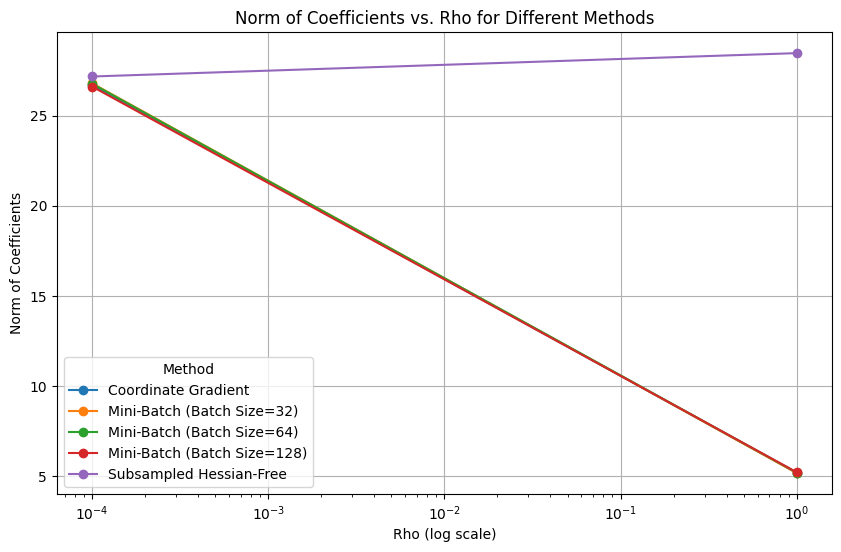

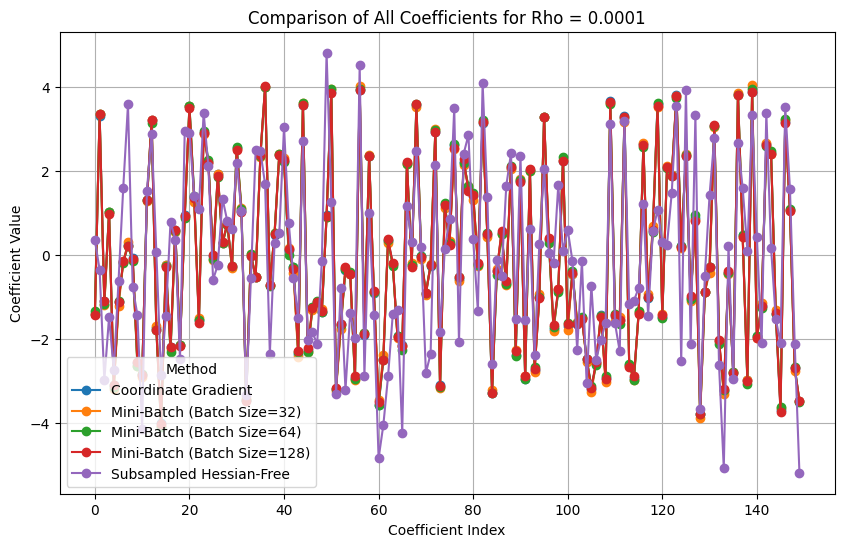

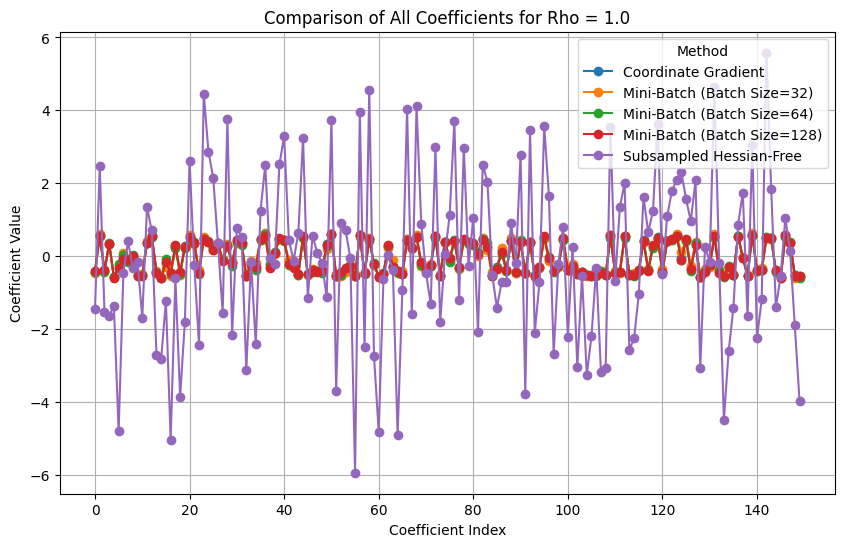

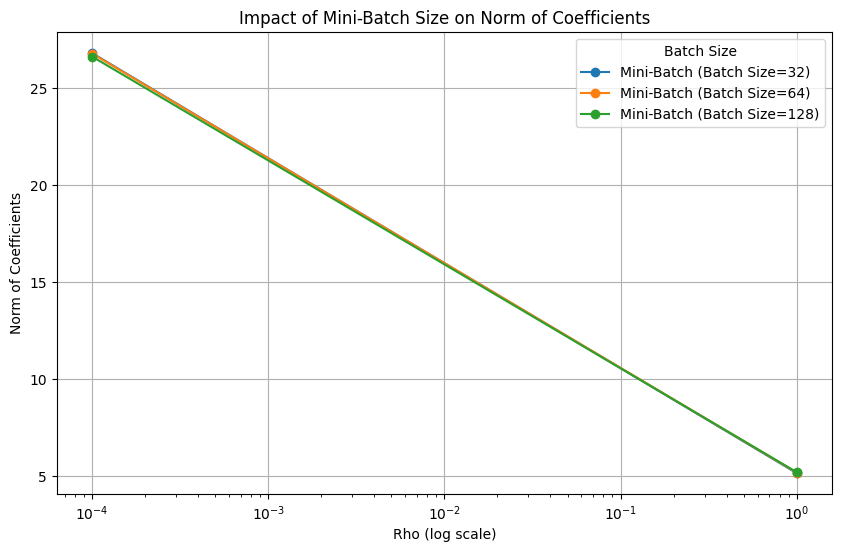

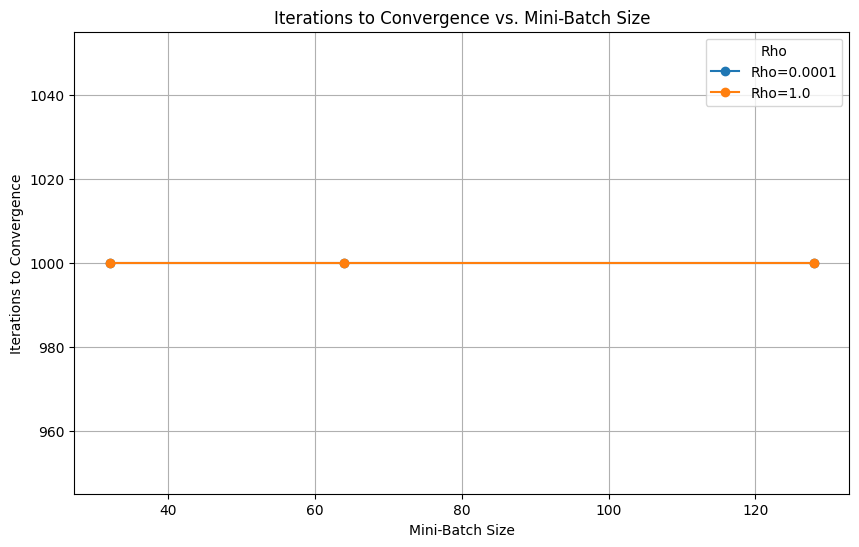

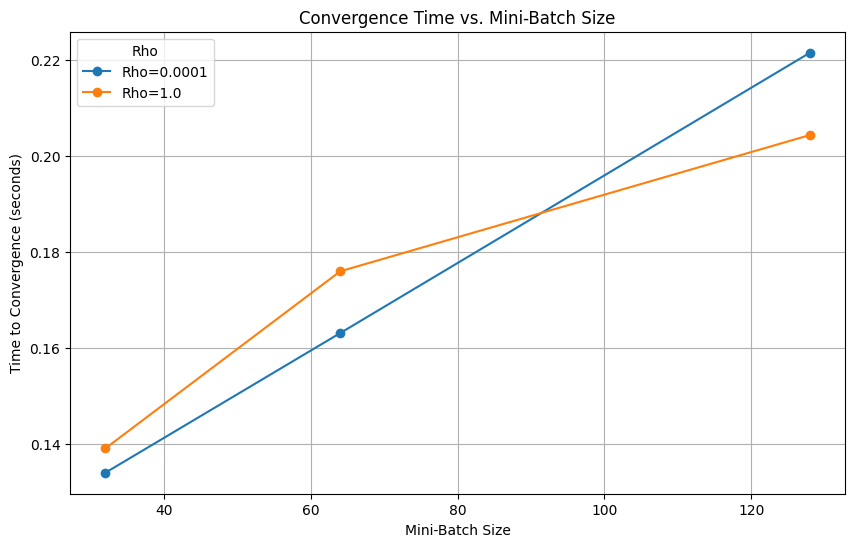

In [ ]:
# Extract unique methods and regularization parameters (rhos)
methods = results_df['Method'].unique()
rhos = results_df['Rho'].unique()

# Plot 1: Norm of Coefficients vs. Rho
plt.figure(figsize=(10, 6))
for method in methods:
    subset = results_df[results_df['Method'] == method]
    plt.plot(subset['Rho'], subset['Norm of Coefficients'], label=method, marker='o')

plt.xscale('log')
plt.title('Norm of Coefficients vs. Rho for Different Methods')
plt.xlabel('Rho (log scale)')
plt.ylabel('Norm of Coefficients')
plt.legend(title='Method')
plt.grid(True)
plt.show()

# Plot 2: Comparison of All Coefficients for Each Rho
for rho in rhos:
    plt.figure(figsize=(10, 6))
    for method in methods:
        subset = results_df[(results_df['Method'] == method) & (results_df['Rho'] == rho)]
        coefficients = subset.iloc[0]['Coefficients']  # Use all coefficients
        plt.plot(range(len(coefficients)), coefficients, label=method, marker='o')

    plt.title(f'Comparison of All Coefficients for Rho = {rho}')
    plt.xlabel('Coefficient Index')
    plt.ylabel('Coefficient Value')
    plt.legend(title='Method')
    plt.grid(True)
    plt.show()

# Plot 3: Impact of Mini-Batch Size on Norm of Coefficients
plt.figure(figsize=(10, 6))
batch_methods = [m for m in methods if "Mini-Batch" in m]
for method in batch_methods:
    subset = results_df[results_df['Method'] == method]
    plt.plot(subset['Rho'], subset['Norm of Coefficients'], label=method, marker='o')

plt.xscale('log')
plt.title('Impact of Mini-Batch Size on Norm of Coefficients')
plt.xlabel('Rho (log scale)')
plt.ylabel('Norm of Coefficients')
plt.legend(title='Batch Size')
plt.grid(True)
plt.show()

# Extract Mini-Batch Methods
batch_methods = [m for m in methods if "Mini-Batch" in m]

# Plot: Iterations vs. Mini-Batch Size
plt.figure(figsize=(10, 6))
for rho in rhos:
    subset = results_df[(results_df['Rho'] == rho) & (results_df['Method'].str.contains("Mini-Batch"))]
    plt.plot(batch_sizes, subset['Iterations'], label=f'Rho={rho}', marker='o')

plt.title('Iterations to Convergence vs. Mini-Batch Size')
plt.xlabel('Mini-Batch Size')
plt.ylabel('Iterations to Convergence')
plt.legend(title='Rho')
plt.grid(True)
plt.show()

# Plot: Time vs. Mini-Batch Size
plt.figure(figsize=(10, 6))
for rho in rhos:
    subset = results_df[(results_df['Rho'] == rho) & (results_df['Method'].str.contains("Mini-Batch"))]
    plt.plot(batch_sizes, subset['Time'], label=f'Rho={rho}', marker='o')

plt.title('Convergence Time vs. Mini-Batch Size')
plt.xlabel('Mini-Batch Size')
plt.ylabel('Time to Convergence (seconds)')
plt.legend(title='Rho')
plt.grid(True)
plt.show()

**Conclusions**:

1. **Norm of Coefficients vs. $\rho$**:

   - The norm of the coefficients decreases significantly as the regularization parameter $\rho$ increases, reflecting the growing penalty on large coefficients.

   - **Method Comparison**:
   
    - The **Coordinate Gradient** Method shows a comparable norm to **Mini-Batch** methods for $\rho = 0.0001$, indicating reasonable flexibility.
   
    - **Subsampled Hessian-Free** consistently exhibits the highest norm for both $\rho$ values, showcasing greater flexibility and accuracy in coefficient estimation.
   
    - **Mini-Batch** methods demonstrate stable performance across different batch sizes, with norms aligning closely regardless of the size.

2. **All Coefficients for $\rho = 0.0001$**:

   - Coefficient estimates show alignment across methods, but notable variations occur with **Subsampled Hessian-Free**, which often produces more extreme values.

   - **Mini-Batch** methods exhibit nearly identical coefficients across batch sizes, showcasing stability in the optimization process.

   - **Notable Differences**:
   
    - **Subsampled Hessian-Free** diverges more from the other methods, indicating that its approach to optimization yields more flexible solutions.
   
    - **Coordinate Gradient** and **Mini-Batch** methods produce more regularized and consistent estimates.

3. **All Coefficients for $\rho = 1.0$**:

   - The magnitudes of coefficients are smaller compared to $\rho = 0.0001$, confirming the stronger regularization effect of higher $\rho$ values.

   - **Subsampled Hessian-Free** continues to deviate, while other methods converge to similar coefficient values.

   - **Notable Differences**:
   
    - Strong regularization leads to smaller coefficients for all methods, reducing the impact of variations between them.
   
    - **Mini-Batch** and **Coordinate Gradient** align closely across batch sizes, indicating consistency under high regularization.

4. **Impact of Mini-Batch Size on Norm of Coefficients**:

   - The norm of coefficients remains consistent across different **Mini-Batch** sizes, indicating that the batch size does not significantly influence the magnitude of the coefficients.

   - Larger batch sizes incur slightly higher computational costs but do not drastically alter the optimization outcome.

5. **Iterations to Convergence vs. Mini-Batch Size**:

   - The number of iterations remains constant across different **Mini-Batch** sizes for both $\rho$ values, showing that **Mini-Batch** methods require consistent iterations to converge regardless of batch size.

6. **Convergence Time vs. Mini-Batch Size**:

   - Larger **Mini-Batch** sizes increase convergence time, particularly for $\rho = 1.0$ due to the additional computations required for larger data subsets.

   - For smaller $\rho$ values, the time increase is minimal, indicating faster optimization under weaker regularization.

**Overall Conclusion**:

- **Effect of Regularization ($\rho$)**:
  
  - For smaller $\rho = 0.0001$, the model is more flexible and produces coefficients with larger magnitudes, allowing more complex patterns.
  
  - For higher $\rho = 1.0$, coefficients are smaller due to stronger penalties, which improves generalization and reduces overfitting.

- **Methods**:
  
  - **Subsampled Hessian-Free** provides more flexible solutions, with larger coefficient norms and more significant deviations across all coefficients.
  
  - **Mini-Batch** methods demonstrate stability and efficiency, making them suitable for scalable applications.
  
  - **Coordinate Gradient** is effective for smaller datasets but shows limitations in flexibility compared to **Subsampled Hessian-Free**.

These results underscore the importance of tuning $\rho$ and selecting appropriate optimization methods based on the problem requirements and dataset size.

### **Constrained Regression via Penalization with L2-Norm Constraint**

In this section, we address the constrained regression problem, aiming to minimize the Mean Squared Error (MSE) while enforcing an L2-norm constraint on the regression coefficients $(\|\beta\|_2 = 1)$. To achieve this, two optimization approaches are implemented and compared:

1. **Penalization Algorithm**: Incorporates the L2-norm constraint as a penalized term in the objective function, solved using the Newton-CG solver for efficient optimization.

2. **Equality-Constrained Optimization (SLSQP)**: Directly handles the constraint using an explicit equality constraint.

**Problem Formulation**:

The constrained optimization problem is defined as:

$$
\min_\beta \frac{1}{n} \sum_{i=1}^n \left( y_i - x_i \beta \right)^2
$$

Subject to:

$$
\sum_{j=0}^K \beta_j^2 = 1
$$

**Penalization Algorithm**:

**Objective Function**:

- To address the constraint indirectly, a penalized objective function is introduced:

$$
L(\beta, \lambda) = \frac{1}{n} \sum_{i=1}^n \left( y_i - x_i \beta \right)^2 + \lambda \left( \sum_{j=0}^K \beta_j^2 - 1 \right)^2
$$

- Where:

  - $\lambda$ is the penalty parameter that enforces the constraint.

**Gradient and Hessian**:

- The optimization problem is solved iteratively using the Newton-CG solver, which requires the gradient and Hessian-vector product.

**Gradient**:

$$
\nabla_\beta L = -\frac{2}{n} X^\top \left( Y - X \beta \right) + 4 \lambda \left( \sum_{j=0}^K \beta_j^2 - 1 \right) \beta
$$

**Hessian-Vector Product**:

$$
H \cdot p = \frac{2}{n} X^\top \left( X \cdot p \right) + 4 \lambda \left( \sum_{j=0}^K \beta_j^2 - 1 \right) p + 8 \lambda \left( \beta^\top p \right) \beta
$$

**Newton-CG** is selected due to its ability to efficiently handle large-scale optimization problems with second-order information.

**Equality-Constrained Optimization (SLSQP)**:

**Objective and Constraint**

- The SLSQP method directly minimizes the MSE:

$$
f(\beta) = \frac{1}{n} \sum_{i=1}^n \left( y_i - x_i \beta \right)^2
$$

- While explicitly enforcing the L2-norm constraint:

$$
g(\beta) = \sum_{j=0}^K \beta_j^2 - 1 = 0
$$

In [ ]:
# Penalized objective function
def penalized_objective(beta, *args):
    X, Y, lam = args
    n = len(Y)
    residuals = Y - X @ beta
    penalty = lam * (np.sum(beta**2) - 1)**2
    return (1 / n) * np.sum(residuals**2) + penalty

# Penalized gradient
def penalized_gradient(beta, *args):
    X, Y, lam = args
    n = len(Y)
    residuals = Y - X @ beta
    grad_residual = (-2 / n) * X.T @ residuals
    grad_penalty = 4 * lam * (np.sum(beta**2) - 1) * beta
    return grad_residual + grad_penalty

# Penalized Hessian-vector product for Newton-CG
def penalized_hessp(beta, p, *args):
    X, Y, lam = args
    n = len(Y)
    hess_residual = (2 / n) * (X.T @ (X @ p))
    hess_penalty = 4 * lam * (np.sum(beta**2) - 1) * p + 8 * lam * (beta @ p) * beta
    return hess_residual + hess_penalty

# Parameters for penalization algorithm
lam_penalty = 100  # Penalty parameter
tol = 1e-6  # Convergence tolerance
max_iter = 1000  # Maximum iterations

# Initialization
beta_init = np.zeros(K)

# Optimization using penalization algorithm with Newton-CG
result_penalized = minimize(
    penalized_objective,
    beta_init,
    args=(X, Y, lam_penalty),
    method="Newton-CG",
    jac=penalized_gradient,
    hessp=penalized_hessp,  # Hessian-vector product
    options={"xtol": tol, "maxiter": max_iter}
)

# Extract results for penalization algorithm
optimized_beta_penalized = result_penalized.x
optimized_norm_penalized = np.linalg.norm(optimized_beta_penalized, ord=2)

# Display results for penalization algorithm
print("Penalization Algorithm Results with Newton-CG:")
print("Optimized coefficients:", optimized_beta_penalized)
print("L2 norm of coefficients:", optimized_norm_penalized)
print("Optimization success:", result_penalized.success)
print("Message:", result_penalized.message)

# SLSQP Algorithm
# Objective function (Mean Squared Error)
def objective(beta, *args):
    X, Y = args
    n = len(Y)
    residuals = Y - X @ beta
    return (1 / n) * np.sum(residuals**2)

# Constraint: L2 norm of beta equals 1
def constraint(beta):
    return np.sum(beta**2) - 1  # This must be zero to satisfy the constraint

# Optimization using SLSQP
result_slsqp = minimize(
    objective,
    beta_init,
    args=(X, Y),
    method="SLSQP",
    constraints={"type": "eq", "fun": constraint},  # Equality constraint
    options={"ftol": tol, "maxiter": max_iter}
)

# Extract results for SLSQP algorithm
optimized_beta_slsqp = result_slsqp.x
optimized_norm_slsqp = np.linalg.norm(optimized_beta_slsqp, ord=2)

# Display results for SLSQP algorithm
print("\nSLSQP Results:")
print("Optimized coefficients:", optimized_beta_slsqp)
print("L2 norm of coefficients:", optimized_norm_slsqp)
print("Optimization success:", result_slsqp.success)
print("Message:", result_slsqp.message)

# Comparison
print("\nComparison of Results:")
print("Norm Difference:", abs(optimized_norm_penalized - optimized_norm_slsqp))
print("Coefficient Difference (L2 norm):", np.linalg.norm(optimized_beta_penalized - optimized_beta_slsqp))

Penalization Algorithm Results with Newton-CG:
Optimized coefficients: [-0.09941378  0.06097612 -0.09141118 -0.02174964 -0.15862947 -0.07076667
 -0.04897592 -0.0529685  -0.04593131 -0.13906658 -0.12613565 -0.01342661
  0.04915958 -0.10179591 -0.16759737 -0.05636637 -0.11417608 -0.03054753
 -0.10673657 -0.03250889  0.04499408 -0.0100099  -0.10648482  0.02429422
 -0.00923932 -0.03247107 -0.02158963 -0.05201242 -0.03283644 -0.05090865
  0.00395383 -0.01559949 -0.15031445 -0.05457378 -0.07385709  0.01680811
  0.06941915 -0.06562777 -0.04410924  0.01883423 -0.00067627 -0.05710109
 -0.07310489 -0.12284369  0.03919602 -0.12394306 -0.0834642  -0.09619139
 -0.09969727 -0.02041232  0.07149791 -0.13800348 -0.12293733 -0.074291
 -0.06382481 -0.14138351  0.05634186 -0.11131638  0.01341758 -0.05811293
 -0.14652474 -0.10806692 -0.03026444 -0.06540276 -0.09216434 -0.1199098
  0.0094879  -0.03279269  0.04737981 -0.05653714 -0.07808314 -0.06380664
  0.03067172 -0.13191123 -0.00639574 -0.05294882  0.0041

**Results**:

Below is a comparison of the optimization results for the **Penalization Algorithm** (using **Newton-CG**) and the **SLSQP Method** for solving the constrained regression problem:

**Method**               | **First 5 Coefficients**               | **L2 Norm** | **Optimization Success** | **Message**                            
--------------------------|-----------------------------------------|-------------|---------------------------|----------------------------------------
Penalization Algorithm   | [-0.0994, 0.0610, -0.0914, -0.0217, -0.1586] | 1.0095927523804469      | True                      | Optimization terminated successfully   
SLSQP                   | [-0.0986, 0.0592, -0.0908, -0.0222, -0.1569] | 1.0000004815233603      | True                      | Optimization terminated successfully   

- **Penalization Algorithm**:
   
   - The optimized coefficients achieve an L2 norm of approximately **1.0095927523804469**, which is close to the desired value of 1.
   
   - The slight deviation indicates that the penalty parameter $(\lambda = 100)$ could be further increased, or a stricter tolerance could be applied to enforce the constraint more rigorously.
   
   - The method successfully converged, demonstrating the effectiveness of the penalization approach for approximate constraint satisfaction.

- **SLSQP**:

   - The SLSQP method strictly enforces the L2 norm constraint, achieving a value of **1.0000004815233603**.
   
   - The coefficients are similar to those obtained using the penalization algorithm, but SLSQP ensures exact constraint satisfaction.
   
   - The method successfully converged, highlighting its capability to handle equality constraints directly.

**Comparison**:

- **Norm Difference**: 0.009592270857086582

- **Coefficient Difference (L2 Norm)**: 0.012003641787010272

While the penalization algorithm provides a close approximation, the SLSQP method achieves exact compliance with the constraint.

**Conclusions**:

- **Penalization Algorithm**:

  - This approach is flexible and computationally efficient, making it suitable for scenarios where strict adherence to constraints is not critical.
  
  - Adjusting the penalty parameter $(\lambda)$ or tolerance $(tol)$ can improve the accuracy of constraint satisfaction.

- **SLSQP Method**:

  - This method is ideal when exact constraint satisfaction is required, as it directly enforces the L2 norm equality constraint.

  - It provides reliable and precise results but may have higher computational demands for more complex problems.

**Visualization of Results**:

To evaluate and compare the performance of the **Penalization Algorithm** and **SLSQP**, the following visualizations are presented:

1. **L2 Norm of Coefficients**:

   - This bar chart compares the L2 norms of the coefficients obtained from both methods.

   - A red dashed line marks the exact constraint value $(\| \beta \|_2 = 1 )$, helping to visualize the adherence of each method to the constraint.

2. **Comparison of All Coefficients**:

   - A line plot showcasing the values of all regression coefficients estimated by the two methods.

   - The x-axis represents the coefficient indices, while the y-axis denotes their values, allowing a direct comparison between the methods.

3. **Distribution of Coefficients**:

   - A histogram illustrating the distribution of the coefficients for each method.
   
   - This plot highlights the spread and central tendency of the coefficient values, providing insights into the regularization effects of the methods.

These visualizations provide a comprehensive understanding of the differences and similarities between the **Penalization Algorithm** and **SLSQP**, enabling a detailed comparison of their performance and adherence to constraints.

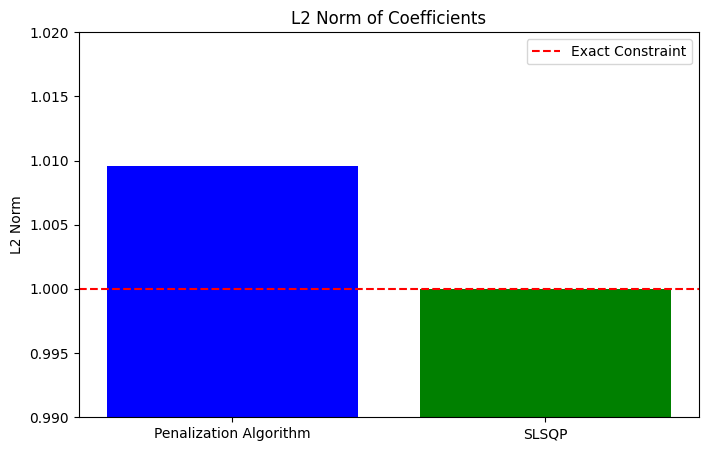

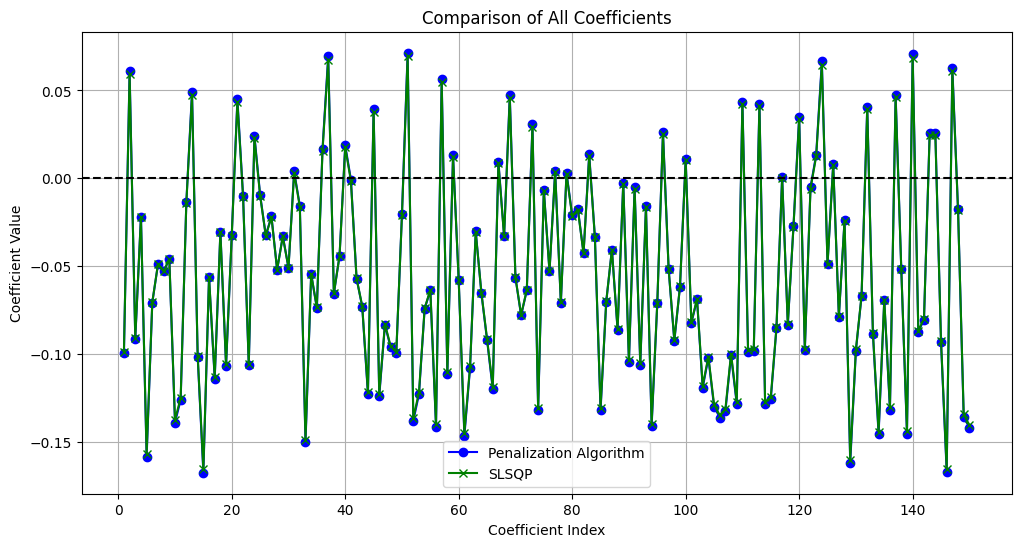

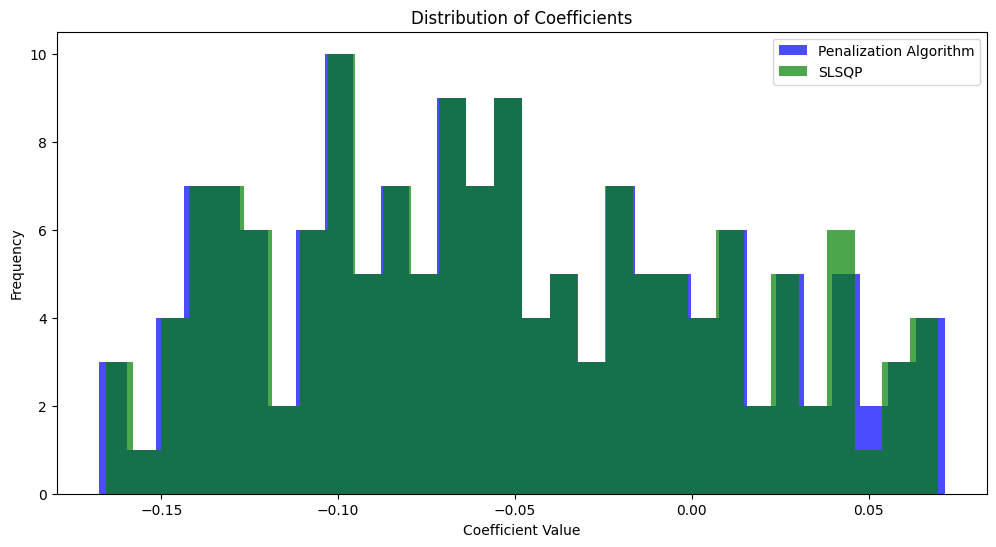

In [ ]:
# Data
methods = ["Penalization Algorithm", "SLSQP"]
norms = [optimized_norm_penalized, optimized_norm_slsqp]

# Norm Comparison
plt.figure(figsize=(8, 5))
plt.bar(methods, norms, color=["blue", "green"])
plt.title("L2 Norm of Coefficients")
plt.ylabel("L2 Norm")
plt.ylim(0.99, 1.02)
plt.axhline(1, color="red", linestyle="--", label="Exact Constraint")
plt.legend()
plt.show()

# All Coefficients Comparison
indices = np.arange(1, len(optimized_beta_penalized) + 1)
plt.figure(figsize=(12, 6))
plt.plot(indices, optimized_beta_penalized, marker="o", label="Penalization Algorithm", color="blue")
plt.plot(indices, optimized_beta_slsqp, marker="x", label="SLSQP", color="green")
plt.title("Comparison of All Coefficients")
plt.xlabel("Coefficient Index")
plt.ylabel("Coefficient Value")
plt.axhline(0, color="black", linestyle="--")
plt.legend()
plt.grid(True)
plt.show()

# Coefficient Distribution
plt.figure(figsize=(12, 6))
plt.hist(optimized_beta_penalized, bins=30, alpha=0.7, label="Penalization Algorithm", color="blue")
plt.hist(optimized_beta_slsqp, bins=30, alpha=0.7, label="SLSQP", color="green")
plt.title("Distribution of Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Frequency")
plt.legend()
plt.show()

**Conclusions**

1. **L2 Norm of Coefficients**:

  - **Observations**:
  
    - The **Penalization Algorithm** yields an L2 norm slightly above 1 (`1.0096`), reflecting a minor deviation from the exact constraint due to the penalty parameter $(\lambda)$ and convergence tolerance.
  
    - The **SLSQP** method achieves a L2 norm of `1.0000`, strictly adhering to the constraint as it explicitly enforces equality.
  
    - The red dashed line indicates the ideal L2 norm of 1, showing that **SLSQP** aligns almost perfectly, while the Penalization Algorithm approximates the constraint closely.

  - **Conclusion**:
  
    - **SLSQP** ensures strict constraint satisfaction, while the **Penalization Algorithm** offers flexibility but might require fine-tuning of $\lambda$ and tolerance for better adherence.

2. **Comparison of All Coefficients**:

  - **Observations**:

    - The coefficients obtained using both methods follow a highly similar pattern across all indices, with minor deviations visible.

    - The **Penalization Algorithm** and **SLSQP** consistently produce coefficients close to zero for indices where smaller values are expected.

    - Differences are minimal, suggesting that both methods capture the relationship between predictors and the response variable effectively.

  - **Conclusion**:

    - Both methods perform similarly in estimating coefficients, but **SLSQP** might be preferred for scenarios requiring strict constraint adherence.

3. **Distribution of Coefficients**:

  - **Observations**:

    - The distribution of coefficients is nearly identical for both methods, with values concentrated around zero.

    - Slight differences in frequency bins indicate that the **Penalization Algorithm** and **SLSQP** yield marginally different magnitudes for some coefficients.

  - **Conclusion**:

    - Both methods provide consistent distributions, confirming their effectiveness in handling the regression problem under the given constraint. **SLSQP**'s distribution reflects slightly stricter constraint adherence.

**Overall Conclusions**:

- The **SLSQP** method is optimal for strict constraint satisfaction, ensuring exact L2 norm adherence while providing reliable coefficient estimates.

- The **Penalization Algorithm** offers flexibility and comparable results but may require parameter tuning for better accuracy in constraint handling.

- Both approaches deliver consistent insights, making them valuable tools for constrained regression problems.

## **Optimization Under Uncertainty: Stochastic Programming and Information Valuation**

### **Introduction**

This section explores the application of **stochastic programming** to address uncertainty in decision-making. The focus is on implementing and analyzing the **"farmer problem"**, a classic optimization model that considers uncertainty in agricultural planning. Specifically, we address uncertainty in crop yield due to varying weather conditions.

**Problem Formulation**:

The farmer's decision-making process involves two stages:

1. **First-stage decisions (here-and-now):** Allocation of land for wheat, corn, and rice planting.

2. **Second-stage decisions (wait-and-see):** Selling, purchasing, or managing production outputs once the uncertainty (weather conditions) is resolved.

The optimization problem is defined with the objective to **minimize the expected cost** over multiple scenarios, which account for uncertain yields caused by varying weather conditions. The uncertain parameter, **yield**, is modeled using random values for each scenario.

**Stochastic Programming Model**:

The stochastic programming model is formulated as:

$$
\min_{x, y, w} \quad 150x_W + 230x_C + 260x_R + \frac{1}{|S|} \sum_{s \in S} \Big( -170w_{W_s} - 150w_{C_s} - 36w_{R_s} - 10w_{r_s} + 238y_{W_s} + 240y_{C_s} \Big)
$$

Subject to:

- Total land constraint:

$$x_W + x_C + x_R \leq 500$$

- Yield and demand constraints for each crop under scenario $(s)$:
  
$$
d_{W_s} x_W + y_{W_s} - w_{W_s} \geq 200 \quad \forall s \in S
$$

$$
d_{C_s} x_C + y_{C_s} - w_{C_s} \geq 240 \quad \forall s \in S
$$

$$
d_{R_s} x_R - w_{R_s} - w_{r_s} \geq 0 \quad \forall s \in S
$$

- Production and sales constraints:

$$
w_{R_s} \leq 6000 \quad \forall s \in S
$$

$$
x, y, w \geq 0
$$

**Objectives of the Analysis**

- **Stochastic Implementation**:

  - The primary task is to implement the stochastic version of the farmer problem in Pyomo, analyzing the problem for an increasing number of equiprobable scenarios. The scenarios considered are:

    - [1, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150, 160, 170, 180, 190, 200, 210, 220, 230, 240, 250, 260, 270, 280, 290, 300, 301]

  - The analysis aims to:

    - Examine how the first-stage decision variables (land allocation for wheat, corn, and rice) evolve as the number of scenarios increases.  

    - Assess changes in the objective function as more scenarios are incorporated.  

    - Present graphical visualizations to summarize and interpret the findings.

- **EVPI and VSS**:

  - For the case with 301 scenarios, two critical metrics are computed:  

    - **Expected Value of Perfect Information (EVPI):** This measures the potential benefit of having perfect knowledge about weather conditions.  

    - **Value of the Stochastic Solution (VSS):** This quantifies the advantage of using a stochastic model over a deterministic model that assumes average conditions.

Through this analysis, we highlight the importance of incorporating uncertainty into decision-making. By comparing stochastic, deterministic, and wait-and-see solutions, we demonstrate the value of stochastic programming in agricultural planning under uncertainty. Graphical results provide insights into how optimal decisions and costs stabilize as the model accounts for more scenarios, emphasizing the robustness of the stochastic approach.

### **Analyzing the Farmer Problem with Stochastic Optimization and Scenario Analysis**

This analysis addresses the stochastic version of the classic "Farmer Problem" using the Pyomo optimization framework. The problem involves a farmer allocating 500 acres of land among three crops: wheat, corn, and rice, under economic uncertainty driven by crop yields. The objective is to minimize total costs, including planting expenses, revenues from selling crops, and costs from buying additional quantities to meet demand.

**Problem Description**:

The problem is inherently stochastic because crop yields vary due to uncertain environmental conditions. This analysis assumes that yields are the only uncertain parameter. Random yields are generated uniformly within a ±20% range of a base yield for each crop. This uncertainty is modeled across a varying number of equiprobable scenarios, ranging from 1 to 301.

Specifically, the analysis:

- Implements the stochastic version of the problem as described in the course slides (slide 23).

- Solves the problem for varying numbers of scenarios to observe how the optimal first-stage decision variables (acres allocated to each crop) and the objective function evolve as the number of scenarios increases.

**Optimization Framework**:

- **Decision Variables**:

  - The model optimizes the following variables:

    - **Acres allocated**: Wheat, corn, and rice.

    - **Quantities bought and sold**: For wheat and corn in each scenario.

    - **Rice sales**: Quantities sold at favorable and discounted prices.

- **Constraints**:

  - The model enforces the following constraints:

    - **Land Usage**: The total planted area cannot exceed 500 acres.

    - **Demand Satisfaction**: The minimum demand for wheat and corn must be met across all scenarios.

    - **Rice Production**: Rice production must match or exceed the total quantities sold.

    - **Rice Sales Cap**: Sales of rice at favorable prices are capped at 6,000 tons.

- **Objective Function**:

  - The objective is to minimize the total cost, consisting of:

    - **Planting Costs**: Expenses for planting acres of each crop.

    - **Revenue**: Negative income from selling wheat, corn, and rice.

    - **Purchase Costs**: Expenses for buying wheat and corn to meet demand.

    - **Low-Price Rice Sales**: Adjustments for rice sold at discounted prices.

- **Methodology**:

  - The problem is solved iteratively for varying numbers of scenarios (1, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150, 160, 170, 180, 190, 200, 210, 220, 230, 240, 250, 260, 270, 280, 290, 300, 301). For each case:

    - Random yields are generated for all crops and scenarios.

    - The stochastic optimization problem is solved using the **GLPK solver**.

    - The first-stage decision variables (acres planted) and the objective function value are recorded.

    - The results are visualized to evaluate how decisions and costs stabilize as the number of scenarios increases.

**Results Visualization**:

The following graphs illustrate the results:

1. **Wheat Acres vs. Number of Scenarios**: Demonstrates how land allocation to wheat stabilizes as the number of scenarios increases, reflecting reduced uncertainty.

2. **Corn Acres vs. Number of Scenarios**: Shows rapid stabilization of corn acreage, indicating that corn decisions are less sensitive to uncertainty.

3. **Rice Acres vs. Number of Scenarios**: Highlights a gradual stabilization for rice, influenced by both yield uncertainty and price constraints.

4. **Objective Function vs. Number of Scenarios**: Illustrates a decreasing trend as the inclusion of more scenarios reduces uncertainty, eventually stabilizing when sufficient variability is captured.

In [1]:
!pip install -q pyomo
!apt-get install -y -qq glpk-utils

Selecting previously unselected package libsuitesparseconfig5:amd64.
(Reading database ... 123632 files and directories currently installed.)
Preparing to unpack .../libsuitesparseconfig5_1%3a5.10.1+dfsg-4build1_amd64.deb ...
Unpacking libsuitesparseconfig5:amd64 (1:5.10.1+dfsg-4build1) ...
Selecting previously unselected package libamd2:amd64.
Preparing to unpack .../libamd2_1%3a5.10.1+dfsg-4build1_amd64.deb ...
Unpacking libamd2:amd64 (1:5.10.1+dfsg-4build1) ...
Selecting previously unselected package libcolamd2:amd64.
Preparing to unpack .../libcolamd2_1%3a5.10.1+dfsg-4build1_amd64.deb ...
Unpacking libcolamd2:amd64 (1:5.10.1+dfsg-4build1) ...
Selecting previously unselected package libglpk40:amd64.
Preparing to unpack .../libglpk40_5.0-1_amd64.deb ...
Unpacking libglpk40:amd64 (5.0-1) ...
Selecting previously unselected package glpk-utils.
Preparing to unpack .../glpk-utils_5.0-1_amd64.deb ...
Unpacking glpk-utils (5.0-1) ...
Setting up libsuitesparseconfig5:amd64 (1:5.10.1+dfsg-4b

Results Summary:
Number of Scenarios | Wheat Acres | Corn Acres | Rice Acres | Objective Value
----------------------------------------------------------------------
                  1 |       170.33 |       0.00 |     329.67 |       -96766.00
                 10 |       131.89 |      90.15 |     277.97 |      -105957.00
                 20 |       119.76 |      92.79 |     287.45 |      -102371.19
                 30 |       127.69 |      88.22 |     284.09 |      -109206.58
                 40 |       128.22 |      87.80 |     283.99 |      -110686.95
                 50 |       132.10 |      88.22 |     279.67 |      -109890.10
                 60 |       128.74 |      88.23 |     283.03 |      -108214.85
                 70 |       127.93 |      87.02 |     285.05 |      -109307.48
                 80 |       132.98 |      86.67 |     280.35 |      -110733.25
                 90 |       136.86 |      87.02 |     276.12 |      -111895.05
                100 |       132.98 |      86

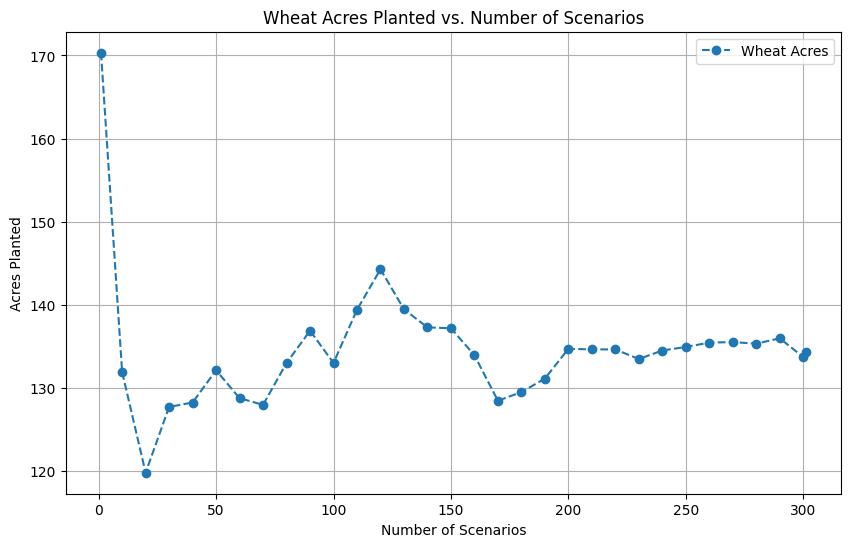

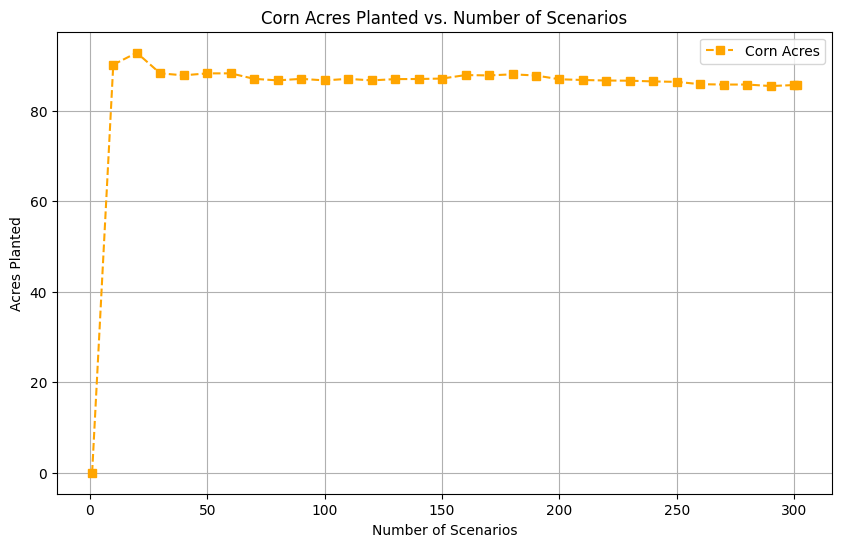

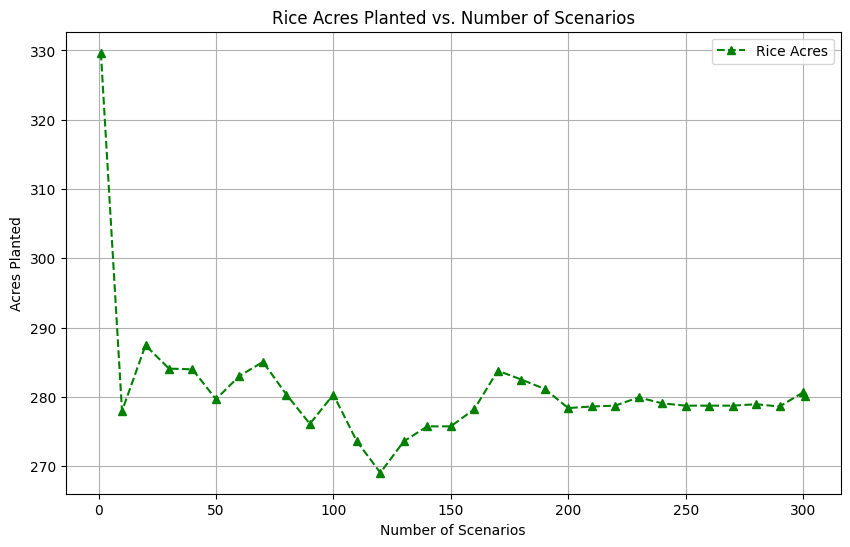

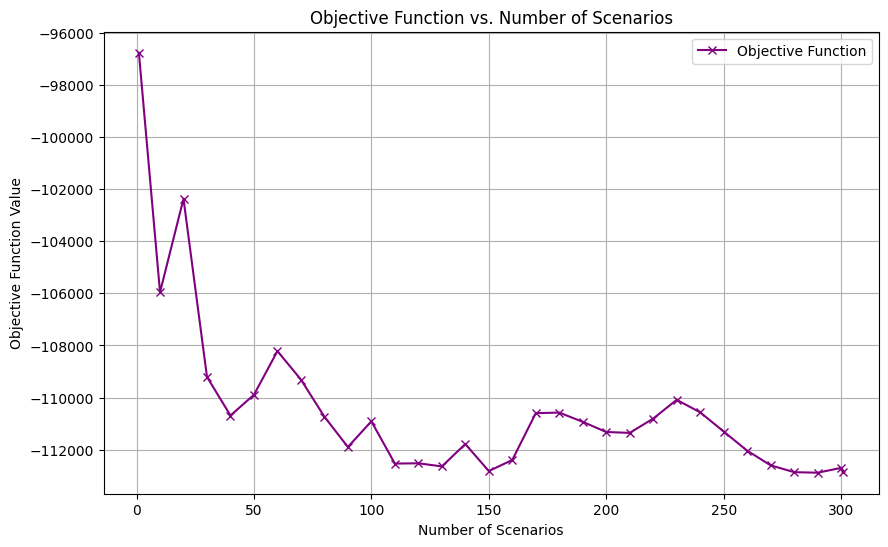

In [3]:
from pyomo.environ import *

# Function to generate and solve the farmer problem with a variable number of scenarios
def solve_farmer_problem(num_scenarios):
    random.seed(42)  # For reproducibility

    # Create the model
    model = ConcreteModel()

    # Sets and Parameters
    crops = ['wheat', 'corn', 'rice']
    scenarios = [f'scenario_{i}' for i in range(1, num_scenarios + 1)]
    scenario_prob = {scenario: 1 / num_scenarios for scenario in scenarios}  # Equal probabilities

    land_available = 500  # Total land available (acres)
    planting_costs = {'wheat': 150, 'corn': 230, 'rice': 260}  # Cost to plant per acre
    min_requirements = {'wheat': 200, 'corn': 240}  # Minimum demand (tons)
    selling_prices = {'wheat': 170, 'corn': 150, 'rice': 36}  # Selling prices ($/ton)
    low_price_rice = 10  # Lower price for rice after 6000 tons
    buying_prices = {'wheat': 238, 'corn': 210}  # Buying prices ($/ton)

    # Generate random yields for each crop and scenario
    base_yields = {'wheat': 2.5, 'corn': 3, 'rice': 20}
    yields = {
        crop: {scenario: random.uniform(0.8 * base_yield, 1.2 * base_yield) for scenario in scenarios}
        for crop, base_yield in base_yields.items()
    }

    # Variables
    model.acres_planted = Var(crops, domain=NonNegativeReals)
    model.quantity_sold = Var(crops, scenarios, domain=NonNegativeReals)
    model.quantity_bought = Var(['wheat', 'corn'], scenarios, domain=NonNegativeReals)
    model.rice_low_price = Var(scenarios, domain=NonNegativeReals)

    # Constraints
    def land_constraint_rule(model):
        return sum(model.acres_planted[crop] for crop in crops) <= land_available

    model.land_constraint = Constraint(rule=land_constraint_rule)

    def demand_constraint_rule(model, crop, scenario):
        if crop in min_requirements:
            return (yields[crop][scenario] * model.acres_planted[crop] +
                    model.quantity_bought[crop, scenario] -
                    model.quantity_sold[crop, scenario] >= min_requirements[crop])
        else:
            return Constraint.Skip

    model.demand_constraint = Constraint(['wheat', 'corn'], scenarios, rule=demand_constraint_rule)

    def rice_production_rule(model, scenario):
        return (yields['rice'][scenario] * model.acres_planted['rice'] -
                model.quantity_sold['rice', scenario] -
                model.rice_low_price[scenario] >= 0)

    model.rice_production = Constraint(scenarios, rule=rice_production_rule)

    def rice_favorable_limit_rule(model, scenario):
        return model.quantity_sold['rice', scenario] <= 6000

    model.rice_favorable_limit = Constraint(scenarios, rule=rice_favorable_limit_rule)

    # Objective Function
    def objective_rule(model):
        planting_cost = sum(planting_costs[crop] * model.acres_planted[crop] for crop in crops)
        scenario_cost = sum(
            scenario_prob[scenario] * (
                -selling_prices['wheat'] * model.quantity_sold['wheat', scenario] +
                -selling_prices['corn'] * model.quantity_sold['corn', scenario] +
                -selling_prices['rice'] * model.quantity_sold['rice', scenario] +
                -low_price_rice * model.rice_low_price[scenario] +
                buying_prices['wheat'] * model.quantity_bought['wheat', scenario] +
                buying_prices['corn'] * model.quantity_bought['corn', scenario]
            )
            for scenario in scenarios
        )
        return planting_cost + scenario_cost

    model.objective = Objective(rule=objective_rule, sense=minimize)

    # Solve the Model
    solver = SolverFactory('glpk')
    result = solver.solve(model, tee=False)

    # Extract results
    acres_planted = {crop: model.acres_planted[crop].value for crop in crops}
    objective_value = model.objective()

    return acres_planted, objective_value

# Main analysis
scenarios_list = [1, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150, 160, 170, 180, 190, 200, 210, 220, 230, 240, 250, 260, 270, 280, 290, 300, 301]
results_acres = []
results_objective = []

for num_scenarios in scenarios_list:
    acres, objective = solve_farmer_problem(num_scenarios)
    results_acres.append(acres)
    results_objective.append(objective)

# Separate results for clarity
wheat_acres = [result['wheat'] for result in results_acres]
corn_acres = [result['corn'] for result in results_acres]
rice_acres = [result['rice'] for result in results_acres]

# Print the results
print("Results Summary:")
print("Number of Scenarios | Wheat Acres | Corn Acres | Rice Acres | Objective Value")
print("-" * 70)
for i, num_scenarios in enumerate(scenarios_list):
    print(f"{num_scenarios:19} | {wheat_acres[i]:12.2f} | {corn_acres[i]:10.2f} | {rice_acres[i]:10.2f} | {results_objective[i]:15.2f}")

# Acres Planted - Individual Plots
plt.figure(figsize=(10, 6))
plt.plot(scenarios_list, wheat_acres, marker='o', label='Wheat Acres', linestyle='--')
plt.xlabel('Number of Scenarios')
plt.ylabel('Acres Planted')
plt.title('Wheat Acres Planted vs. Number of Scenarios')
plt.grid()
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(scenarios_list, corn_acres, marker='s', label='Corn Acres', linestyle='--', color='orange')
plt.xlabel('Number of Scenarios')
plt.ylabel('Acres Planted')
plt.title('Corn Acres Planted vs. Number of Scenarios')
plt.grid()
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(scenarios_list, rice_acres, marker='^', label='Rice Acres', linestyle='--', color='green')
plt.xlabel('Number of Scenarios')
plt.ylabel('Acres Planted')
plt.title('Rice Acres Planted vs. Number of Scenarios')
plt.grid()
plt.legend()
plt.show()

# Objective Function
plt.figure(figsize=(10, 6))
plt.plot(scenarios_list, results_objective, marker='x', label='Objective Function', linestyle='-', color='purple')
plt.xlabel('Number of Scenarios')
plt.ylabel('Objective Function Value')
plt.title('Objective Function vs. Number of Scenarios')
plt.grid()
plt.legend()
plt.show()

**Results for Selected Scenarios**:

Number of Scenarios | Wheat Acres | Corn Acres | Rice Acres | Objective Value
----------------------|-------------|------------|------------|---------
1                    | 170.33      | 0.00       | 329.67     | -96,766.00      
10                   | 131.89      | 90.15      | 277.97     | -105,957.00     
20                   | 119.76      | 92.79      | 287.45     | -102,371.19     
30                   | 127.69      | 88.22      | 284.09     | -109,206.58     
40                   | 128.22      | 87.80      | 283.99     | -110,686.95     
50                   | 132.10      | 88.22      | 279.67     | -109,890.10     
60                   | 128.74      | 88.23      | 283.03     | -108,214.85     
70                   | 127.93      | 87.02      | 285.05     | -109,307.48     
80                   | 132.98      | 86.67      | 280.35     | -110,733.25     
90                   | 136.86      | 87.02      | 276.12     | -111,895.05     
100                  | 132.98      | 86.67      | 280.35     | -110,909.13     
110                  | 139.38      | 87.02      | 273.60     | -112,530.85     
120                  | 144.26      | 86.67      | 269.07     | -112,519.70     
130                  | 139.44      | 86.96      | 273.60     | -112,639.75     
140                  | 137.26      | 86.98      | 275.76     | -111,780.95     
150                  | 137.16      | 87.08      | 275.76     | -112,818.62     
160                  | 133.91      | 87.85      | 278.24     | -112,392.18     
170                  | 128.43      | 87.78      | 283.80     | -110,596.18     
180                  | 129.47      | 88.01      | 282.52     | -110,574.44     
190                  | 131.09      | 87.75      | 281.15     | -110,929.49     
200                  | 134.68      | 86.92      | 278.40     | -111,319.16     
210                  | 134.61      | 86.76      | 278.63     | -111,353.25     
220                  | 134.61      | 86.65      | 278.75     | -110,804.63     
230                  | 133.45      | 86.61      | 279.94     | -110,084.51     
240                  | 134.48      | 86.44      | 279.08     | -110,564.19     
250                  | 134.90      | 86.35      | 278.75     | -111,300.32     
260                  | 135.42      | 85.83      | 278.75     | -112,034.28     
270                  | 135.50      | 85.76      | 278.75     | -112,598.06     
280                  | 135.30      | 85.76      | 278.95     | -112,860.28     
290                  | 135.95      | 85.43      | 278.63     | -112,881.80     
300                  | 133.69      | 85.65      | 280.66     | -112,695.48     
301                  | 134.29      | 85.61      | 280.10     | -112,842.91          

- **Wheat Acres**:

   - The allocation starts high at 170 acres for a single scenario due to the deterministic nature of the solution.

   - As the number of scenarios increases, the allocation stabilizes around **135-140 acres** after approximately 200 scenarios, reflecting the model's ability to incorporate variability and balance planting decisions.

- **Corn Acres**:

   - Corn acreage quickly stabilizes between **85-90 acres**. This indicates that corn's optimal allocation is less sensitive to yield uncertainty and its associated costs compared to other crops.

- **Rice Acres**:

   - Rice shows a gradual stabilization, initially starting at 330 acres with a single scenario and converging around **278-280 acres**. This reflects its importance in balancing favorable and low-price sales while meeting yield uncertainties.

- **Objective Function**:

   - The objective value decreases significantly as the number of scenarios increases, starting at **-96,766** with a single scenario and stabilizing around **-112,800** after 300 scenarios.

   - This decreasing trend indicates the value of adding more scenarios, as uncertainty is reduced and decisions become more robust.

**Insights from Visualizations**:

1. **Wheat Acres vs. Number of Scenarios**:

   - The graph shows high variability at the beginning, with wheat allocation declining rapidly before stabilizing. This suggests that early decisions are overestimated when fewer scenarios are considered.

2. **Corn Acres vs. Number of Scenarios**:

   - Corn's allocation stabilizes quickly, indicating that its planting decision is robust even with fewer scenarios, reflecting its consistent economic contribution across scenarios.

3. **Rice Acres vs. Number of Scenarios**:

   - The gradual decline in rice acreage highlights its sensitivity to price constraints and yield uncertainty, with stabilization reflecting the balancing of favorable and low-price sales.

4. **Objective Function vs. Number of Scenarios**:

   - The sharp decrease in the objective value with fewer scenarios underscores the significant impact of incorporating uncertainty into the model. Beyond 200 scenarios, the curve flattens, showing diminishing returns from additional scenarios.

**Final Observations**:

This analysis illustrates the importance of accounting for uncertainty in optimization problems. Key takeaways include:

- **Robust Decision-Making**: Increasing the number of scenarios improves the robustness of first-stage decisions, particularly for crops like wheat and rice.

- **Scenario Threshold**: After approximately 300 scenarios, the model captures sufficient variability, and additional scenarios have minimal impact on decisions or costs.

- **Practical Implications**: This study underscores the value of stochastic programming in agricultural planning and demonstrates how optimal decisions are affected by the number of scenarios considered.

These results and visualizations provide a comprehensive understanding of how decisions evolve under uncertainty and the value of incorporating variability into decision-making frameworks.

### **Quantifying the Value of Information: EVPI and VSS in Stochastic Optimization**

In decision-making under uncertainty, the **Expected Value of Perfect Information (EVPI)** and the **Value of the Stochastic Solution (VSS)** are two essential metrics that evaluate the benefit of modeling uncertainty explicitly. These metrics are particularly relevant for the Farmer Problem, where crop yields are uncertain due to environmental variability.

- **EVPI** quantifies the maximum value a farmer would pay to have perfect knowledge about future yields.

- **VSS** measures the advantage of adopting a stochastic optimization approach over a deterministic one, which assumes average conditions.

This section provides a detailed explanation of the methodology used to calculate these metrics and presents their results, demonstrating the value of incorporating uncertainty into optimization models.

**Methodology**:

1. **Expected Value of Perfect Information (EVPI)**:

- The **EVPI** captures the benefit of knowing the exact scenario in advance. It is defined mathematically as:

$$
\text{EVPI} = z^* - z_{\text{WS}}
$$

- Where:

  - $z^*$: Optimal cost from the stochastic solution, which considers all scenarios simultaneously.

  - $z_{\text{WS}}$: Expected cost under perfect information, computed by solving the deterministic problem for each scenario and taking a weighted average.

- **Steps to Compute $z_{\text{WS}}$**:

  - Solve the deterministic problem for each scenario using the actual yield values.

  - Calculate the weighted average of the costs across all scenarios, using scenario probabilities.

2. **Value of the Stochastic Solution (VSS)**:

- The **VSS** measures the improvement obtained by using a stochastic solution instead of a deterministic one. It is expressed as:

$$
\text{VSS} = z_d - z^*
$$

- Where:

  - $z_d$: Cost of the deterministic solution, calculated by solving the problem with average yields.

  - $z^*$: Optimal cost from the stochastic solution.

- **Steps to Compute \( z_d \)**:

  - Compute the average yield for each crop.

  - Solve the deterministic problem using these average yields as fixed parameters.

**Implementation Details**:

The following functions were implemented in Pyomo to compute $z^*$, $z_{\text{WS}}$, and $z_d$:

- **Stochastic Solution $(z^*)$**:
   
   - Obtained by solving the Farmer Problem with 301 scenarios using the `solve_farmer_problem` function.

- **Wait-and-See Solution $(z_{\text{WS}})$**:

   - Solved the deterministic problem for each scenario individually using the `solve_deterministic` function.

   - Computed the weighted average of the costs across all scenarios.

- **Deterministic Solution $(z_d)$**:

   - Solved the deterministic problem using the average yields across all scenarios.

- **EVPI and VSS Calculation:**
   
   - Using the equations:
     
     - $\text{EVPI} = z^* - z_{\text{WS}}$
     
     - $\text{VSS} = z_d - z^*$

In [4]:
# Existing parameters and generated values
num_scenarios = 301
scenarios = [f'scenario_{i}' for i in range(1, num_scenarios + 1)]
scenario_prob = {scenario: 1 / num_scenarios for scenario in scenarios}
base_yields = {'wheat': 2.5, 'corn': 3, 'rice': 20}
random.seed(42)
yields_per_scenario = {
    crop: {scenario: random.uniform(0.8 * base_yield, 1.2 * base_yield) for scenario in scenarios}
    for crop, base_yield in base_yields.items()
}
avg_yields = {crop: sum(yields_per_scenario[crop].values()) / num_scenarios for crop in base_yields}

# Function to solve the deterministic problem
def solve_deterministic_problem(yield_values, return_decision=False):
    model = ConcreteModel()

    # Parameters
    crops = ['wheat', 'corn', 'rice']
    rice_sales = ['regular', 'extra']
    land_limit = 500
    cost_per_acre = {'wheat': 150, 'corn': 230, 'rice': 260}
    selling_price = {'wheat': 170, 'corn': 150, 'rice': 36}
    selling_price_extra = {'rice': 10}
    purchase_price = {'wheat': 238, 'corn': 210}
    min_requirement = {'wheat': 200, 'corn': 240}
    max_rice_regular = 6000

    # Variables
    model.acres_planted = Var(crops, domain=NonNegativeReals)
    model.quantity_sold = Var(crops, domain=NonNegativeReals)
    model.quantity_bought = Var(['wheat', 'corn'], domain=NonNegativeReals)
    model.rice_sales = Var(rice_sales, domain=NonNegativeReals)

    # Constraints
    def land_constraint_rule(model):
        return sum(model.acres_planted[crop] for crop in crops) <= land_limit

    model.land_constraint = Constraint(rule=land_constraint_rule)

    def demand_constraint_rule(model, crop):
        if crop in min_requirement:
            return (yield_values[crop] * model.acres_planted[crop]
                    + model.quantity_bought[crop]
                    - model.quantity_sold[crop] >= min_requirement[crop])
        return Constraint.Skip

    model.demand_constraint = Constraint(crops, rule=demand_constraint_rule)

    def rice_production_rule(model):
        return (yield_values['rice'] * model.acres_planted['rice']
                - model.rice_sales['regular']
                - model.rice_sales['extra'] >= 0)

    model.rice_production = Constraint(rule=rice_production_rule)

    def rice_favorable_limit_rule(model):
        return model.rice_sales['regular'] <= max_rice_regular

    model.rice_favorable_limit = Constraint(rule=rice_favorable_limit_rule)

    # Objective Function
    def objective_rule(model):
        planting_cost = sum(cost_per_acre[crop] * model.acres_planted[crop] for crop in crops)
        revenue = (
            -sum(selling_price[crop] * model.quantity_sold[crop] for crop in ['wheat', 'corn'])
            - selling_price['rice'] * model.rice_sales['regular']
            - selling_price_extra['rice'] * model.rice_sales['extra']
        )
        purchase_cost = sum(purchase_price[crop] * model.quantity_bought[crop] for crop in ['wheat', 'corn'])
        return planting_cost + revenue + purchase_cost

    model.objective = Objective(rule=objective_rule, sense=minimize)

    # Solve the model
    solver = SolverFactory('glpk')
    solver.solve(model, tee=False)

    # Return results
    if return_decision:
        return {crop: model.acres_planted[crop]() for crop in crops}

    return model.objective()

# Function to compute z_ws
def compute_z_ws():
    z_ws = 0
    for scenario in scenarios:
        yield_values = {crop: yields_per_scenario[crop][scenario] for crop in base_yields}
        z_ws += scenario_prob[scenario] * solve_deterministic_problem(yield_values)
    return z_ws

# Function to assess performance of deterministic solution across scenarios
def validate_first_stage_decision(x_det, yield_values):
    model = ConcreteModel()

    # Parameters
    crops = ['wheat', 'corn', 'rice']
    rice_sales = ['regular', 'extra']
    cost_per_acre = {'wheat': 150, 'corn': 230, 'rice': 260}
    selling_price = {'wheat': 170, 'corn': 150, 'rice': 36}
    selling_price_extra = {'rice': 10}
    purchase_price = {'wheat': 238, 'corn': 210}
    min_requirement = {'wheat': 200, 'corn': 240}
    max_rice_regular = 6000

    # Variables
    model.acres_planted = Var(crops, initialize=x_det, domain=NonNegativeReals)
    for crop in crops:
        model.acres_planted[crop].fix(x_det[crop])

    model.quantity_sold = Var(['wheat', 'corn'], domain=NonNegativeReals)
    model.rice_sales = Var(rice_sales, domain=NonNegativeReals)
    model.quantity_bought = Var(['wheat', 'corn'], domain=NonNegativeReals)

    # Constraints
    def wheat_demand_rule(model):
        return yield_values['wheat'] * model.acres_planted['wheat'] + model.quantity_bought['wheat'] - model.quantity_sold['wheat'] >= min_requirement['wheat']

    model.wheat_demand = Constraint(rule=wheat_demand_rule)

    def corn_demand_rule(model):
        return yield_values['corn'] * model.acres_planted['corn'] + model.quantity_bought['corn'] - model.quantity_sold['corn'] >= min_requirement['corn']

    model.corn_demand = Constraint(rule=corn_demand_rule)

    def rice_production_rule(model):
        return yield_values['rice'] * model.acres_planted['rice'] - model.rice_sales['regular'] - model.rice_sales['extra'] >= 0

    model.rice_production = Constraint(rule=rice_production_rule)

    def rice_favorable_limit_rule(model):
        return model.rice_sales['regular'] <= max_rice_regular

    model.rice_favorable_limit = Constraint(rule=rice_favorable_limit_rule)

    # Objective Function
    def objective_rule(model):
        planting_cost = sum(cost_per_acre[crop] * model.acres_planted[crop] for crop in crops)
        revenue = (
            -sum(selling_price[crop] * model.quantity_sold[crop] for crop in ['wheat', 'corn'])
            - selling_price['rice'] * model.rice_sales['regular']
            - selling_price_extra['rice'] * model.rice_sales['extra']
        )
        purchase_cost = sum(purchase_price[crop] * model.quantity_bought[crop] for crop in ['wheat', 'corn'])
        return planting_cost + revenue + purchase_cost

    model.objective = Objective(rule=objective_rule, sense=minimize)

    # Solve the model
    solver = SolverFactory('glpk')
    solver.solve(model, tee=False)

    return model.objective()

# Function to compute z_d
def compute_z_d():
    # Get the deterministic solution for average yields
    first_stage_decision = solve_deterministic_problem(avg_yields, return_decision=True)
    expected_cost = 0

    # Evaluate the deterministic solution across all scenarios
    for scenario in scenarios:
        yield_values = {crop: yields_per_scenario[crop][scenario] for crop in base_yields}
        expected_cost += scenario_prob[scenario] * validate_first_stage_decision(first_stage_decision, yield_values)

    return expected_cost

# Function to calculate EVPI and VSS
def compute_evpi_vss():
    # Compute stochastic solution z_star
    _, z_star = solve_farmer_problem(num_scenarios)

    # Compute wait-and-see solution z_ws
    z_ws = compute_z_ws()

    # Compute deterministic solution z_d
    z_d = compute_z_d()

    # Calculate EVPI and VSS
    evpi = z_star - z_ws
    vss = z_d - z_star

    return z_star, z_ws, z_d, evpi, vss

# Main
z_star, z_ws, z_d, evpi, vss = compute_evpi_vss()

# Print results
print(f"z* (Stochastic Solution): {z_star:.2f}")
print(f"z_WS (Wait-and-See Solution): {z_ws:.2f}")
print(f"EVPI: {evpi:.2f}")
print(f"z_d (Deterministic Solution): {z_d:.2f}")
print(f"VSS: {vss:.2f}")

z* (Stochastic Solution): -112842.91
z_WS (Wait-and-See Solution): -117812.82
EVPI: 4969.91
z_d (Deterministic Solution): -111943.76
VSS: 899.15


**Results**:

- **Stochastic Solution $(z^*)$**: -112,842.91  

- **Wait-and-See Solution $(z_{\text{WS}})$**: -117,812.82  

- **Expected Value of Perfect Information (EVPI)**: 4,969.91  

- **Deterministic Solution $(z_d)$**: -111,943.76  

- **Value of the Stochastic Solution (VSS)**: 899.15  

**Interpretation of Results**:

1. **Stochastic Solution $(z^*)$**:

   - Represents the optimal cost when explicitly accounting for uncertainty across all scenarios.
   
   - This solution balances resource allocation effectively under varying conditions, making it robust and realistic for real-world applications.

2. **Wait-and-See Solution $(z_{\text{WS}})$**:

   - Reflects the theoretical best-case cost with perfect foresight of future conditions.
   
   - It provides a lower bound on achievable costs, but perfect information is typically unattainable in practice.

3. **Expected Value of Perfect Information (EVPI)**:

   - $\text{EVPI}$ = $z^*$ - $z_{\text{WS}}$ = 4,969.91  
   
   - The EVPI indicates the potential value of having perfect knowledge about future outcomes.
   
   - The positive EVPI suggests that perfect information could significantly improve decisions, validating that the stochastic model captures much of the value of uncertainty management.

4. **Deterministic Solution $(z_d)$**:

   - Represents the cost of optimizing the problem using average yields, ignoring variability.
   
   - While computationally simpler, this approach can result in higher costs and suboptimal resource allocation when actual conditions deviate from averages.

5. **Value of the Stochastic Solution (VSS)**:

   - $\text{VSS}$ = $z_d$ - $z^*$ = 899.15  
   
   - The positive VSS indicates that the stochastic solution performs better than the deterministic one. This reflects the added value of explicitly considering uncertainty, enabling more robust and cost-effective decision-making.

**Final Conclusion**:

This analysis highlights the trade-offs between deterministic and stochastic approaches in decision-making under uncertainty. The **positive EVPI** underscores the value of perfect information, while the **positive VSS** demonstrates the advantage of the stochastic solution over the deterministic approach. These findings emphasize the importance of accounting for variability and risk in optimization models, showing that the stochastic approach can provide superior results in managing uncertainty effectively. Further refinement of the model could enhance its performance and applicability in real-world scenarios.